# Çiğli geneli çatı segmentasyonu, gölge ve çatı geometrisi

EVKA-5 pilotunda sınanan yöntemin Çiğli'nin **26 mahallesine ve Atatürk OSB'ye** uygulanmış hali.

**Pilottan farkı**
* Çiğli tek bir uydu görüntüsü değil: meta veriye göre **dört ayrı çekimden** (farklı uydu ve tarih) oluşuyor. Güneş yönü, güneş yüksekliği ve çatı kayması her çekim için ayrı ölçülür. Gölge yönü güvenilir ölçülemeyen çekimde yükseklik ve eğim hesaplanmaz, nedeni yazılır.
* Görüntü tek mozaik olarak belleğe alınmaz; karolar diske iner, her binanın çevresi gerektiğinde birleştirilir.
* Yıllık komşu gölgesi GPU'da, 2 m'lik ızgarada hesaplanır.
* Uzun adımlar ara sonuçlarını `calisma/ara/` klasörüne yazar; oturum kapanmadıysa hücre yeniden çalıştırıldığında kaldığı yerden devam eder.

**Çalıştırma:** Çalışma zamanı türü **T4 GPU** → Tümünü çalıştır. Toplam süre görüntü indirme hızına bağlı olarak yaklaşık 45–90 dakika.

**Görüntü lisansı:** Esri World Imagery karoları bu çalışmada Çiğli ölçeğinde (~9 bin karo) indiriliyor. Bu kullanım teknik deneme niteliğindedir; tezde ve yayında lisanslı bir görüntü kaynağıyla yinelenmesi gerekir.

**Hızlı deneme:** Kurulum hücresinde `ORNEK_BINA = 20` yapılırsa her birimden 20 bina işlenir (~10 dakika).

## 0 · Kurulum ve ayarlar

In [1]:
import sys, os, subprocess, json, math, time, re, pickle, unicodedata, collections
COLAB = 'google.colab' in sys.modules
if COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'segment-anything'], check=False)

import numpy as np
import cv2
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from functools import lru_cache
import concurrent.futures as cf
import torch
from shapely.geometry import shape, box, Point, Polygon, LineString
from shapely.ops import polygonize, unary_union
from shapely.strtree import STRtree

ORNEK_BINA = None          # sayı verilirse her birimden o kadar bina işlenir; None = Çiğli'nin tamamı
HEDEF_KAMU = False         # True: yalnız kamu tesislerine (okul, sağlık ocağı, muhtarlık…) düşen binalar
KAMU_ETIKET = ([('amenity', x) for x in ('school', 'kindergarten', 'college', 'university', 'hospital',
                                         'clinic', 'doctors', 'townhall', 'courthouse', 'police',
                                         'fire_station', 'post_office', 'community_centre', 'social_facility',
                                         'library', 'arts_centre', 'theatre', 'animal_shelter', 'marketplace')]
               + [('building', x) for x in ('school', 'kindergarten', 'university', 'hospital', 'civic',
                                            'government', 'public', 'sports_hall')]
               + [('healthcare', 'centre'), ('office', 'government'),
                  ('leisure', 'sports_centre'), ('leisure', 'stadium')])   # kamu_binalari.py ile aynı küme
Z, TS = 19, 256
ESIK_VARSAYILAN = 114.0    # EVKA-5 pilotunun parlaklık eşiği; çekim eşiği ölçülemezse kullanılır

GPU = torch.cuda.is_available()
CIHAZ = 'cuda' if GPU else 'cpu'
print('Colab:', COLAB, '| cihaz:', torch.cuda.get_device_name(0) if GPU else 'CPU', '| kip:', 'kamu tesisleri' if HEDEF_KAMU else (ORNEK_BINA or 'tüm Çiğli'))
CALISMA = 'calisma'
for d in ('karo', 'modeller', 'cikti', 'ara'):
    os.makedirs(f'{CALISMA}/{d}', exist_ok=True)
ETIKET = 'kamu' if HEDEF_KAMU else ('tum' if ORNEK_BINA is None else f'ornek{ORNEK_BINA}')
UA = {'User-Agent': 'YBS-bitirme-cati-gunes/1.0 (akademik arastirma)'}
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 10})


def sadelestir(s):
    s = unicodedata.normalize('NFD', s or '')
    s = ''.join(c for c in s if unicodedata.category(c) != 'Mn')
    s = s.translate(str.maketrans('ıİşŞğĞçÇöÖüÜ', 'iIsSgGcCoOuU')).lower()
    return ''.join(ch for ch in s if ch.isalnum())


def ara_kaydet(ad, nesne):
    with open(f'{CALISMA}/ara/{ad}_{ETIKET}.pkl', 'wb') as f:
        pickle.dump(nesne, f)


def ara_yukle(ad):
    p = f'{CALISMA}/ara/{ad}_{ETIKET}.pkl'
    return pickle.load(open(p, 'rb')) if os.path.exists(p) else None

Colab: True | cihaz: Tesla T4 | kip: tüm Çiğli


## 1 · Birimler: Çiğli'nin mahalleleri ve Atatürk OSB

Sınırlar OpenStreetMap idari sınır ilişkilerinden (admin_level 8) üretilir. OSM'de Atatürk Organize Sanayi Bölgesi ayrı bir birim olarak tanımlı; önceki mahalle modelinde yoktu, burada sanayi çatıları için ayrı raporlanır.

26 mahalle + 1 OSB | toplam 131.4 km² | 0.234 m/piksel


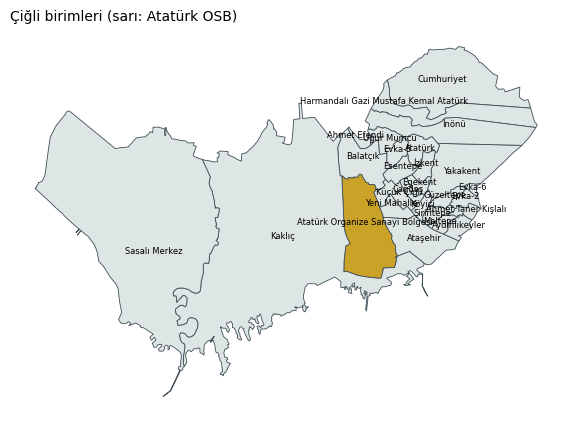

In [2]:
AYNALAR = ('https://overpass-api.de/api/interpreter', 'https://overpass.private.coffee/api/interpreter',
           'https://maps.mail.ru/osm/tools/overpass/api/interpreter', 'https://overpass.kumi.systems/api/interpreter')


def overpass(sorgu, deneme=6):
    for i in range(deneme):
        uc = AYNALAR[i % len(AYNALAR)]
        try:
            r = requests.post(uc, data={'data': sorgu}, headers=UA, timeout=240)
            if r.status_code == 200:
                return r.json()
            print(f'  {uc.split("/")[2]} HTTP {r.status_code}')
        except requests.RequestException as e:
            print(f'  {uc.split("/")[2]} {type(e).__name__}')
        time.sleep(10 * (i + 1))
    return None


d = overpass("""[out:json][timeout:180];
area["boundary"="administrative"]["admin_level"="6"]["name"="Çiğli"]->.ilce;
rel(area.ilce)["boundary"="administrative"]["admin_level"="8"];
out geom;""")
assert d, 'Overpass yanıt vermedi; hücreyi yeniden çalıştırın'
BIRIMLER = []
for e in d['elements']:
    cizgi = [LineString([(p['lon'], p['lat']) for p in m['geometry']]) for m in e.get('members', [])
             if m.get('type') == 'way' and m.get('role') in ('outer', '') and 'geometry' in m]
    pg = list(polygonize(unary_union(cizgi)))
    if not pg:
        continue
    ad = e['tags'].get('name', '?')
    BIRIMLER.append(dict(ad=ad.replace(' Mahallesi', ''), tur='OSB' if 'Sanayi' in ad else 'mahalle', geom=unary_union(pg)))
BIRIMLER.sort(key=lambda b: (b['tur'], b['ad']))
CIGLI = unary_union([b['geom'] for b in BIRIMLER])
LON_C, LAT_C = CIGLI.centroid.x, CIGLI.centroid.y
MPP = 156543.03392 * math.cos(math.radians(LAT_C)) / (1 << Z)
KM2 = 111.32 * math.cos(math.radians(LAT_C)) * 110.57
print(f"{sum(b['tur'] == 'mahalle' for b in BIRIMLER)} mahalle + {sum(b['tur'] == 'OSB' for b in BIRIMLER)} OSB | "
      f"toplam {CIGLI.area * KM2:.1f} km² | {MPP:.3f} m/piksel")
fig, ax = plt.subplots(figsize=(8, 5))
for b in BIRIMLER:
    for p in getattr(b['geom'], 'geoms', [b['geom']]):
        ax.fill(*p.exterior.xy, color='#C9A227' if b['tur'] == 'OSB' else '#DDE6E4', ec='#3F4D55', lw=0.6)
    c = b['geom'].representative_point()
    ax.text(c.x, c.y, b['ad'], fontsize=6, ha='center')
ax.set_aspect(1 / math.cos(math.radians(LAT_C))); ax.axis('off')
ax.set_title('Çiğli birimleri (sarı: Atatürk OSB)', loc='left')
plt.show()

## 2 · Bina ayak izleri: OpenStreetMap

Çiğli sınırının 300 m çevresi dahil indirilir; sınır dışındaki binalar yalnızca gölge engeli olarak kullanılır. Yoğun karolar Overpass'te zaman aşımına düşerse dörde bölünür; inemeyen karo sessizce atlanmaz, hücre durur.

In [3]:
def lonlat2g(lon, lat):
    n = (1 << Z) * TS
    return (lon + 180.0) / 360.0 * n, (1 - math.asinh(math.tan(math.radians(lat))) / math.pi) / 2 * n


def g2lonlat(gx, gy):
    n = (1 << Z) * TS
    return gx / n * 360.0 - 180.0, math.degrees(math.atan(math.sinh(math.pi * (1 - 2 * gy / n))))


def poligon_alan(g):
    x, y = g[:, 0] - g[:, 0].mean(), g[:, 1] - g[:, 1].mean()
    return abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1))) / 2


PAY = 0.003
TAMPON = CIGLI.buffer(PAY)
x0, y0, x1, y1 = TAMPON.bounds
kuyruk = []
for lat in np.arange(y0, y1, 0.04):
    for lon in np.arange(x0, x1, 0.04):
        k = (float(lon), float(lat), float(min(lon + 0.04, x1)), float(min(lat + 0.04, y1)))
        if TAMPON.intersects(box(*k)):
            kuyruk.append((k, 0))
elemanlar, basarisiz = {}, []
TESIS_GEOM = []
if HEDEF_KAMU:
    # KISA YOL: ilçenin ~79 bin binasını taramak yerine önce kamu tesisleri çekilir,
    # sonra yalnız onların çevresindeki binalar indirilir. İlçe geneli karo taraması
    # atlanır (kuyruk boşaltılır); Overpass yükü ~80 sorgudan ~12 sorguya iner.
    if 'KAMU_VERI' in globals():
        # Gömülü veri (scripts/defter_kamu.py): cache/kamu_cigli.geojson tesisleri + OSM bina önbelleğinden
        # tesis çevresindeki binalar, Overpass çıktısıyla aynı biçimde. Overpass'e hiç gidilmez.
        import base64, gzip
        _v = json.loads(gzip.decompress(base64.b64decode(KAMU_VERI)))
        kj = {'elements': _v['tesisler']}
        for el in _v['binalar']:
            elemanlar[(el['type'], el['id'])] = el
        print(f"gömülü veri kullanılıyor ({_v['meta']})")
    else:
        _parca = []
        for _k, _v in KAMU_ETIKET:
            for _t in ('node', 'way', 'relation'):
                _parca.append(f'{_t}["{_k}"="{_v}"](area.ilce);')
        kj = overpass('[out:json][timeout:240];area["boundary"="administrative"]["admin_level"="6"]["name"="Çiğli"]->.ilce;('
                      + ''.join(_parca) + ');out geom;')
        assert kj, 'kamu tesisi sorgusu başarısız'
    odak = []
    for e in kj['elements']:
        if e['type'] == 'node':
            TESIS_GEOM.append(Point(e['lon'], e['lat']))
            odak.append((e['lat'], e['lon'], 60.0))
            continue
        g = e.get('geometry') or [q for m in e.get('members', []) if m.get('role') in ('outer', '')
                                  for q in m.get('geometry', [])]
        if len(g) < 4:
            continue
        try:
            pg = Polygon([(q['lon'], q['lat']) for q in g])
        except Exception:
            continue
        if not pg.is_valid or pg.area <= 0:
            continue
        TESIS_GEOM.append(pg)
        bx = pg.bounds
        yari = max(111320 * (bx[3] - bx[1]), 111320 * math.cos(math.radians(LAT_C)) * (bx[2] - bx[0])) / 2
        odak.append((pg.centroid.y, pg.centroid.x, min(max(yari + 80, 80), 400)))
    # around: filtresi Overpass'te pahalı (birleşik 15'li/5'li sorgular 504 veriyordu).
    # Bunun yerine her tesisin çevresi kutuya çevrilir, üst üste binen kutular birleştirilir
    # ve aşağıdaki karo kuyruğuna verilir: kutu sorgusu dizinden okunur, zaman aşımında dörde bölünür.
    _kutular = [box(lo - r / (111320 * math.cos(math.radians(la))), la - r / 111320,
                    lo + r / (111320 * math.cos(math.radians(la))), la + r / 111320) for la, lo, r in odak]
    _birlesik = unary_union(_kutular)
    kuyruk = [] if elemanlar else [(tuple(float(v) for v in p.bounds), 0) for p in getattr(_birlesik, 'geoms', [_birlesik])]
    print(f'{len(TESIS_GEOM)} kamu tesisi | {len(odak)} tesis çevresi | {len(elemanlar)} gömülü bina | '
          f'{len(kuyruk)} Overpass kutusu (ilçe taraması atlandı)')
toplam = len(kuyruk)
while kuyruk:
    (a, b_, c, e_), der = kuyruk.pop(0)
    j = overpass(f'[out:json][timeout:180];(way["building"]({b_},{a},{e_},{c});relation["building"]({b_},{a},{e_},{c}););out geom qt;', deneme=3)
    if j is None:
        if der >= 3:
            basarisiz.append((a, b_, c, e_))
            continue
        mx, my = (a + c) / 2, (b_ + e_) / 2
        kuyruk = [((a, b_, mx, my), der + 1), ((mx, b_, c, my), der + 1), ((a, my, mx, e_), der + 1), ((mx, my, c, e_), der + 1)] + kuyruk
        print('  zaman aşımı: karo dörde bölündü')
        continue
    for el in j['elements']:
        elemanlar[(el['type'], el['id'])] = el
    time.sleep(1)
assert not basarisiz, f'{len(basarisiz)} Overpass karosu inmedi: {basarisiz}'

birim_agac = STRtree([b['geom'] for b in BIRIMLER])
BINALAR = []
for (tip, kimlik), e in elemanlar.items():
    halkalar = [e.get('geometry', [])] if tip == 'way' else \
        [m['geometry'] for m in e.get('members', []) if m.get('role') == 'outer' and 'geometry' in m]
    for g in halkalar:
        if len(g) < 4 or (g[0]['lat'], g[0]['lon']) != (g[-1]['lat'], g[-1]['lon']):
            continue
        ll = np.array([(p['lon'], p['lat']) for p in g])
        gp = np.array([lonlat2g(lo, la) for lo, la in ll])
        alan = poligon_alan(gp) * MPP ** 2
        if alan < 25 or alan > 60000:
            continue
        c = Point(ll[:-1, 0].mean(), ll[:-1, 1].mean())
        birim = next((BIRIMLER[int(i)]['ad'] for i in birim_agac.query(c) if BIRIMLER[int(i)]['geom'].contains(c)), None)
        BINALAR.append(dict(osm=f'{tip}/{kimlik}', g=gp, ayak_alan=float(alan), birim=birim, lon=c.x, lat=c.y))

for b in BINALAR:
    b['analiz'] = b['birim'] is not None
if ORNEK_BINA:
    for ad in {b['birim'] for b in BINALAR if b['birim']}:
        grup = [b for b in BINALAR if b['birim'] == ad]
        mlon, mlat = np.median([b['lon'] for b in grup]), np.median([b['lat'] for b in grup])
        grup.sort(key=lambda b: (b['lon'] - mlon) ** 2 + (b['lat'] - mlat) ** 2)
        for b in grup[ORNEK_BINA:]:
            b['analiz'] = False
if HEDEF_KAMU:
    tesisler = TESIS_GEOM
    bina_nokta = [Point(b['lon'], b['lat']) for b in BINALAR]
    bina_geom = [Polygon([g2lonlat(float(x), float(y)) for x, y in b['g']]) for b in BINALAR]
    nokta_agac, geom_agac = STRtree(bina_nokta), STRtree(bina_geom)
    hedef = set()
    for gt in tesisler:
        if gt.geom_type == 'Polygon':
            hedef |= {int(i) for i in nokta_agac.query(gt) if gt.contains(bina_nokta[int(i)])}
        else:
            ic = {int(i) for i in geom_agac.query(gt) if bina_geom[int(i)].contains(gt)}
            if not ic:
                yakin = [(bina_geom[int(i)].distance(gt), int(i)) for i in geom_agac.query(gt.buffer(30 / 111320))]
                ic = {min(yakin)[1]} if yakin else set()
            hedef |= ic
    for _i, b in enumerate(BINALAR):
        b['analiz'] = b['analiz'] and _i in hedef
    print(f'{len(tesisler)} kamu tesisi -> {len(hedef)} bina hedeflendi')
ANALIZ = [i for i, b in enumerate(BINALAR) if b['analiz']]
KUTU_AGAC = STRtree([box(*b['g'].min(0), *b['g'].max(0)) for b in BINALAR])


def komsular(gx0, gy0, gx1, gy1):
    return [int(i) for i in KUTU_AGAC.query(box(gx0, gy0, gx1, gy1))]


print(f'{toplam} Overpass karosu | {len(BINALAR)} bina poligonu (tampon dahil) | işlenecek {len(ANALIZ)} bina')
print(pd.Series([BINALAR[i]['birim'] for i in ANALIZ]).value_counts().rename('bina').to_frame().T.to_string())

  overpass-api.de HTTP 429
  overpass.private.coffee HTTP 504
  maps.mail.ru HTTP 504
  zaman aşımı: karo dörde bölündü
  overpass-api.de HTTP 504
  overpass.private.coffee HTTP 504
  overpass-api.de HTTP 504
  overpass.private.coffee HTTP 504
  maps.mail.ru HTTP 504
  zaman aşımı: karo dörde bölündü
  overpass-api.de HTTP 504
  overpass.private.coffee HTTP 504
  overpass-api.de HTTP 504
  overpass.private.coffee ReadTimeout
  overpass-api.de HTTP 429
  overpass.private.coffee HTTP 504
  overpass-api.de HTTP 504
  overpass.private.coffee HTTP 504
  overpass-api.de HTTP 504
  overpass-api.de HTTP 504
  overpass-api.de HTTP 504
  overpass-api.de HTTP 504
  overpass.private.coffee HTTP 504
  overpass-api.de HTTP 504
  overpass.private.coffee HTTP 504
  overpass-api.de HTTP 504
  overpass-api.de HTTP 504
  overpass.private.coffee HTTP 504
  overpass-api.de HTTP 504
20 Overpass karosu | 33728 bina poligonu (tampon dahil) | işlenecek 20291 bina
      Şirintepe  Güzeltepe  Ataşehir  Sasalı Me

## 3 · Uydu çekimleri

Esri Wayback'in en yeni sürümündeki meta veri katmanından, Çiğli'yi kesen çekim poligonları alınır. Her bina, merkezinin düştüğü çekime atanır.

In [5]:
cfg = requests.get('https://s3-us-west-2.amazonaws.com/config.maptiles.arcgis.com/waybackconfig.json', timeout=60).json()
surum = max(cfg.values(), key=lambda v: re.search(r'(\d{4}-\d{2}-\d{2})', v['itemTitle']).group(1))
info = requests.get(surum['metadataLayerUrl'], params={'f': 'json'}, timeout=60).json()
katman = next(l['id'] for l in info['layers'] if l['name'].startswith('30cm'))
bx = CIGLI.bounds
yanit = requests.get(f"{surum['metadataLayerUrl']}/{katman}/query", timeout=240, params=dict(
    geometry=f'{bx[0]},{bx[1]},{bx[2]},{bx[3]}', geometryType='esriGeometryEnvelope', inSR=4326, outSR=4326,
    spatialRel='esriSpatialRelIntersects', outFields='SRC_DATE,SRC_DESC,SRC_RES,NICE_NAME',
    returnGeometry='true', f='geojson')).json()
parcalar = collections.defaultdict(list)
bilgi = {}
for f in yanit['features']:
    p = f['properties']
    kod_ = f"{p['SRC_DESC']} {p['SRC_DATE']}"
    parcalar[kod_].append(shape(f['geometry']))
    bilgi[kod_] = dict(uydu=p['SRC_DESC'], tarih=str(p['SRC_DATE']), cozunurluk=p['SRC_RES'], urun=p.get('NICE_NAME'))
CEKIMLER = [dict(kod=k, geom=unary_union(v), **bilgi[k]) for k, v in parcalar.items()]
cekim_agac = STRtree([c['geom'] for c in CEKIMLER])
for b in BINALAR:
    pt = Point(b['lon'], b['lat'])
    b['cekim'] = next((CEKIMLER[int(i)]['kod'] for i in cekim_agac.query(pt) if CEKIMLER[int(i)]['geom'].contains(pt)), None)
tablo = pd.DataFrame([dict(çekim=c['kod'], uydu=c['uydu'], tarih=c['tarih'], çözünürlük_m=c['cozunurluk'],
                           işlenecek_bina=sum(1 for i in ANALIZ if BINALAR[i]['cekim'] == c['kod'])) for c in CEKIMLER])
print(surum['itemTitle'])
print(tablo[tablo['işlenecek_bina'] > 0].sort_values('işlenecek_bina', ascending=False).to_string(index=False))
print('çekime atanamayan bina:', sum(1 for i in ANALIZ if BINALAR[i]['cekim'] is None))

World Imagery (Wayback 2026-08-05)
        çekim uydu    tarih  çözünürlük_m  işlenecek_bina
LG03 20260114 LG03 20260114          0.34           17397
LG05 20260219 LG05 20260219          0.34            2348
WV02 20251012 WV02 20251012          0.50             502
LG02 20260120 LG02 20260120          0.34              40
çekime atanamayan bina: 4


## 4 · Karolar: indirme ve okuma

Birinci aşamada binaların (12 m payla) kapladığı karolar iner. Gölge boyu için gereken, gölge yönündeki karolar güneş yönü ölçüldükten sonra ikinci aşamada iner.

In [6]:
URL = 'https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'


def karo_yolu(x, y):
    return f'{CALISMA}/karo/{Z}_{x}_{y}.jpg'


def karo_indir(xy):
    p = karo_yolu(*xy)
    if os.path.exists(p) and os.path.getsize(p) > 1000:
        return True
    for _ in range(3):
        try:
            r = requests.get(URL.format(z=Z, x=xy[0], y=xy[1]), headers=UA, timeout=45)
            if r.status_code == 200 and len(r.content) > 1000:
                with open(p, 'wb') as f:
                    f.write(r.content)
                return True
        except requests.RequestException:
            pass
        time.sleep(2)
    return False


def karolari_indir(karolar, etiket):
    karolar = list(karolar)
    eksik = [k for k in karolar if not (os.path.exists(karo_yolu(*k)) and os.path.getsize(karo_yolu(*k)) > 1000)]
    t0 = time.time()
    print(f'{etiket}: {len(karolar)} karo, indirilecek {len(eksik)}')
    for tur in range(4):
        if not eksik:
            break
        with cf.ThreadPoolExecutor(12) as ex:
            sonuc = list(ex.map(karo_indir, eksik))
        eksik = [k for k, ok in zip(eksik, sonuc) if not ok]
        if eksik:
            print(f'  tur {tur + 1}: {len(eksik)} karo inmedi, bekleyip yeniden deneniyor')
            time.sleep(30)
    assert not eksik, f'{len(eksik)} karo inmedi; hücreyi yeniden çalıştırın'
    print(f'  tamam ({time.time() - t0:.0f} s)')


def kutu_karolar(gx0, gy0, gx1, gy1):
    return {(x, y) for x in range(int(gx0 // TS), int(gx1 // TS) + 1) for y in range(int(gy0 // TS), int(gy1 // TS) + 1)}


@lru_cache(maxsize=2000)
def karo_oku(x, y):
    p = karo_yolu(x, y)
    return np.array(Image.open(p).convert('RGB')) if os.path.exists(p) else None


def pencere_oku(gx0, gy0, gx1, gy1):
    gx0, gy0, gx1, gy1 = int(gx0), int(gy0), int(gx1), int(gy1)
    img = np.zeros((gy1 - gy0, gx1 - gx0, 3), np.uint8)
    var = np.zeros((gy1 - gy0, gx1 - gx0), bool)
    for ty in range(gy0 // TS, (gy1 - 1) // TS + 1):
        for tx in range(gx0 // TS, (gx1 - 1) // TS + 1):
            k = karo_oku(tx, ty)
            if k is None:
                continue
            sx0, sy0 = max(gx0, tx * TS), max(gy0, ty * TS)
            sx1, sy1 = min(gx1, (tx + 1) * TS), min(gy1, (ty + 1) * TS)
            img[sy0 - gy0:sy1 - gy0, sx0 - gx0:sx1 - gx0] = k[sy0 - ty * TS:sy1 - ty * TS, sx0 - tx * TS:sx1 - tx * TS]
            var[sy0 - gy0:sy1 - gy0, sx0 - gx0:sx1 - gx0] = True
    return img, var


def poligon_maske(g, gx0, gy0, h, w):
    m = np.zeros((h, w), np.uint8)
    cv2.fillPoly(m, [np.round(g - [gx0, gy0]).astype(np.int32)], 1)
    return m.astype(bool)


PAY_PX = 12 / MPP
KAROLAR1 = set()
for i in ANALIZ:
    g = BINALAR[i]['g']
    KAROLAR1 |= kutu_karolar(*(g.min(0) - PAY_PX), *(g.max(0) + PAY_PX))
karolari_indir(sorted(KAROLAR1), 'Aşama 1 · bina karoları')

Aşama 1 · bina karoları: 8502 karo, indirilecek 8502
  tamam (190 s)


## 5 · Çekim bazında güneş geometrisi ve çatı kayması

Her çekim için binaların en yoğun olduğu en fazla 8 pencerede (1024 px):
1. Parlaklık eşiği (Otsu) çekimin kendi görüntüsünden bulunur.
2. **Gölge yönü:** taban ayak izleri her yöne kaydırılır, gölgeyle en çok çakışan yön seçilir. Ölçüt, tepe yönü ile **tam ters yönün** oranıdır: 2,0'ın altındaysa çekim *güvenilmez* sayılır. (Yoğun dokuda her yönde gölge bulunduğu için tepe/medyan oranı yanıltıcı; EVKA-5 pilotunda güvenilir çıkan LG03 çekimi bu ölçütle yanlışlıkla elenmişti.)
3. **Güneş yüksekliği:** çekim tarihinde (± 7 gün) güneşin bu azimuta geldiği an.
4. **Çatı kayması:** ayak izi ile kiremit rengi arasındaki çapraz korelasyon.

WV02 20251012 örnek pencereleri: 128 karo, indirilecek 69
  tamam (2 s)
WV02 20251012: gölge 328.5° güneş 148.5° (tepe/ters 1.62, tepe/medyan 1.53) | yerel ~11:21, güneş yüksekliği 35.9–41.6° | kayma +0.9 m D, -1.9 m G | GÜVENİLMEZ: gölge yönü belirsiz
LG03 20260114 örnek pencereleri: 128 karo, indirilecek 9
  tamam (0 s)
LG03 20260114: gölge 323.0° güneş 143.0° (tepe/ters 4.00, tepe/medyan 1.87) | yerel ~10:52, güneş yüksekliği 19.6–22.4° | kayma +2.8 m D, +3.3 m G | güvenilir
LG02 20260120 örnek pencereleri: 128 karo, indirilecek 128
  tamam (4 s)
LG02 20260120: gölge 329.0° güneş 149.0° (tepe/ters 1.87, tepe/medyan 1.36) | yerel ~11:24, güneş yüksekliği 23.6–27.0° | kayma -1.4 m D, +4.7 m G | GÜVENİLMEZ: gölge yönü belirsiz
LG05 20260219 örnek pencereleri: 128 karo, indirilecek 25
  tamam (1 s)
LG05 20260219: gölge 3.0° güneş 183.0° (tepe/ters 2.33, tepe/medyan 2.42) | yerel ~13:35, güneş yüksekliği 37.8–42.8° | kayma -1.9 m D, +1.9 m G | güvenilir


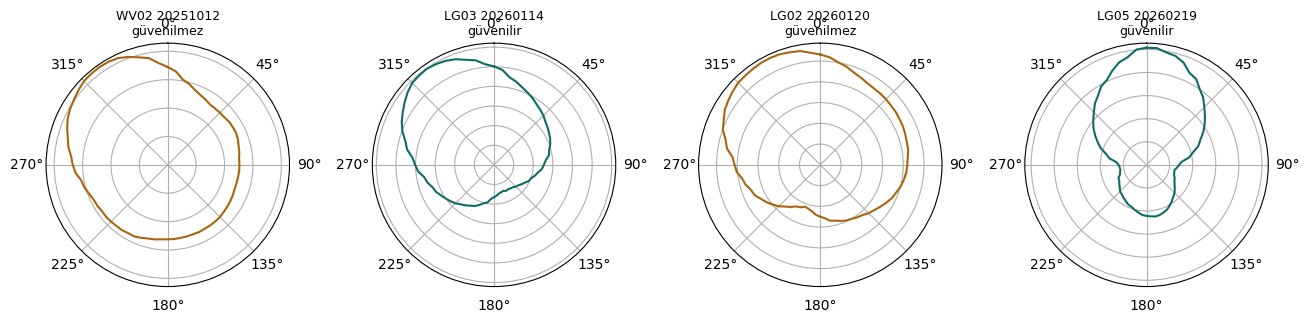

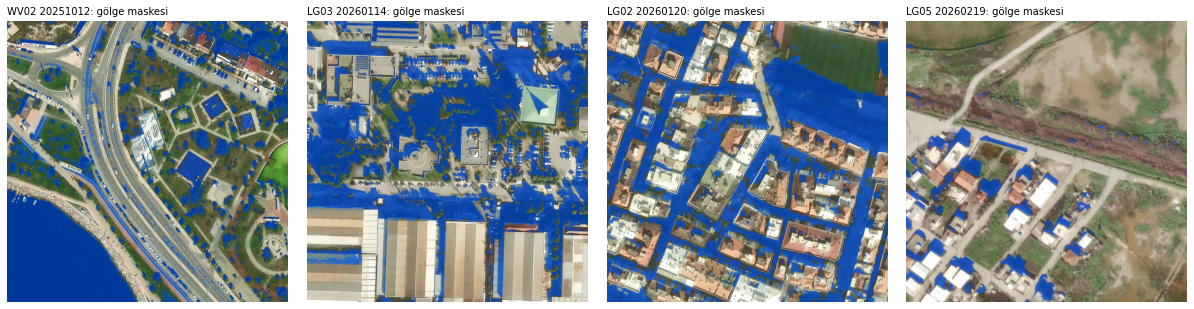

In [7]:
def parlaklik(img):
    return 0.299 * img[..., 0].astype(np.float32) + 0.587 * img[..., 1] + 0.114 * img[..., 2]


def golge_maskesi(img, var, esik):
    f = img.astype(np.float32)
    y = 0.299 * f[..., 0] + 0.587 * f[..., 1] + 0.114 * f[..., 2]
    mavilik = f[..., 2] / (f.sum(-1) + 1e-6)
    s = ((y < esik) & (mavilik > 0.30)) | (y < 62)
    s = cv2.morphologyEx(s.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)).astype(bool)
    return s & var


def kiremit_hsv(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 0] < 14) | (hsv[..., 0] > 170)) & (hsv[..., 1] > 70) & (hsv[..., 2] > 90)


def kaydir(M, dx, dy):
    out = np.zeros_like(M)
    h, w = M.shape
    if abs(dx) >= w or abs(dy) >= h:
        return out
    xs, xd = (slice(0, w - dx), slice(dx, w)) if dx >= 0 else (slice(-dx, w), slice(0, w + dx))
    ys, yd = (slice(0, h - dy), slice(dy, h)) if dy >= 0 else (slice(-dy, h), slice(0, h + dy))
    out[yd, xd] = M[ys, xs]
    return out


def gunes_konumu(utc, lat, lon):
    """NOAA yaklaşımı (~0,1°). Dönüş: azimut (0 = kuzey, saat yönü), yükseklik; derece."""
    t = (np.asarray(utc, 'datetime64[s]') - np.datetime64('2000-01-01T12:00:00')).astype(float) / 86400.0
    L = np.radians((280.460 + 0.9856474 * t) % 360)
    g = np.radians((357.528 + 0.9856003 * t) % 360)
    lam = L + np.radians(1.915) * np.sin(g) + np.radians(0.020) * np.sin(2 * g)
    eps = np.radians(23.439 - 4e-7 * t)
    ra = np.arctan2(np.cos(eps) * np.sin(lam), np.cos(lam))
    dec = np.arcsin(np.sin(eps) * np.sin(lam))
    Hs = np.radians(((18.697374558 + 24.06570982441908 * t) % 24) * 15 + lon) - ra
    fi = np.radians(lat)
    el = np.arcsin(np.sin(fi) * np.sin(dec) + np.cos(fi) * np.cos(dec) * np.cos(Hs))
    az = np.arctan2(-np.sin(Hs), np.tan(dec) * np.cos(fi) - np.sin(fi) * np.cos(Hs))
    return np.degrees(az) % 360, np.degrees(el)


PENCERE = 1024
CEKIM_PARAM = ara_yukle('cekim_param') or {}
GORSEL = {}
for ck in CEKIMLER:
    uyeler = [i for i, b in enumerate(BINALAR) if b['cekim'] == ck['kod']]
    n_analiz = sum(1 for i in uyeler if BINALAR[i]['analiz'])
    if n_analiz == 0 or ck['kod'] in CEKIM_PARAM:
        continue
    say = collections.Counter((int(BINALAR[i]['g'][:, 0].mean() // PENCERE), int(BINALAR[i]['g'][:, 1].mean() // PENCERE)) for i in uyeler)
    aday = sorted([k for k, n in say.items() if n >= 6], key=lambda k: say[k])
    if len(aday) > 8:   # en yoğun doku yerine üst-orta yoğunluk: bitişik binalar gölge yönünü bulanıklaştırıyor
        bas = max(int(len(aday) * 0.7) - 4, 0)
        aday = aday[bas:bas + 8]
    pencereler = aday
    if not pencereler:
        CEKIM_PARAM[ck['kod']] = dict(guvenilir=False, neden='yoğun pencere yok', esik=ESIK_VARSAYILAN, kayma=(0, 0), n=n_analiz)
        continue
    karolar = set()
    for px_, py_ in pencereler:
        karolar |= kutu_karolar(px_ * PENCERE, py_ * PENCERE, (px_ + 1) * PENCERE - 1, (py_ + 1) * PENCERE - 1)
    karolari_indir(sorted(karolar), f'{ck["kod"]} örnek pencereleri')
    veri = []
    for px_, py_ in pencereler:
        img, var = pencere_oku(px_ * PENCERE, py_ * PENCERE, (px_ + 1) * PENCERE, (py_ + 1) * PENCERE)
        veri.append((px_ * PENCERE, py_ * PENCERE, img, var))
    ornek = np.concatenate([parlaklik(img)[var][::7] for _, _, img, var in veri]).clip(0, 255).astype(np.uint8)
    esik = float(cv2.threshold(ornek.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0])
    Fd, Sd, Vd, kor = [], [], [], None
    for gx0, gy0, img, var in veri:
        F = np.zeros((PENCERE, PENCERE), np.uint8)
        for j in komsular(gx0, gy0, gx0 + PENCERE, gy0 + PENCERE):
            cv2.fillPoly(F, [np.round(BINALAR[j]['g'] - [gx0, gy0]).astype(np.int32)], 1)
        S = golge_maskesi(img, var, esik)
        Fd.append(cv2.resize(F, (PENCERE // 4,) * 2, interpolation=cv2.INTER_NEAREST).astype(bool))
        Sd.append(cv2.resize(S.astype(np.uint8), (PENCERE // 4,) * 2, interpolation=cv2.INTER_AREA) > 0.5)
        Vd.append(cv2.resize(var.astype(np.uint8), (PENCERE // 4,) * 2, interpolation=cv2.INTER_NEAREST).astype(bool))
        k2 = cv2.resize((kiremit_hsv(img) & var).astype(np.float32), (PENCERE // 2,) * 2, interpolation=cv2.INTER_AREA)
        f2 = cv2.resize(F.astype(np.float32), (PENCERE // 2,) * 2, interpolation=cv2.INTER_AREA)
        if k2.sum() > 50:
            k2 -= k2.mean(); f2 -= f2.mean()
            c_ = np.real(np.fft.ifft2(np.fft.fft2(k2) * np.conj(np.fft.fft2(f2))))
            kor = c_ if kor is None else kor + c_
        if ck['kod'] not in GORSEL:
            GORSEL[ck['kod']] = (gx0, gy0, img, S)

    def yon_skoru(az):
        t = n = 0
        for f, s, v in zip(Fd, Sd, Vd):
            for r_m in (5, 10, 15):
                r = r_m / (MPP * 4)
                K = kaydir(f, int(round(r * math.sin(math.radians(az)))), int(round(-r * math.cos(math.radians(az))))) & ~f & v
                n += K.sum()
                t += (K & s).sum()
        return t / max(n, 1)

    kaba = np.array([(az, yon_skoru(az)) for az in range(0, 360, 5)])
    a0 = kaba[kaba[:, 1].argmax(), 0]
    ince = np.array([(az, yon_skoru(az)) for az in np.arange(a0 - 6, a0 + 6.1, 0.5)])
    golge_yonu = float(ince[ince[:, 1].argmax(), 0]) % 360
    gunes_az = (golge_yonu + 180) % 360
    oran = float(ince[:, 1].max() / max(np.median(kaba[:, 1]), 1e-6))
    zit_oran = float(ince[:, 1].max() / max(yon_skoru((golge_yonu + 180) % 360), 1e-6))
    kayma = (0, 0)
    if kor is not None:
        r_ = int(15 / (MPP * 2))
        bolge = np.zeros_like(kor, bool)
        bolge[:r_, :r_] = bolge[:r_, -r_:] = bolge[-r_:, :r_] = bolge[-r_:, -r_:] = True
        iy, ix = np.unravel_index(np.argmax(np.where(bolge, kor, -np.inf)), kor.shape)
        kayma = (int((ix if ix < kor.shape[1] // 2 else ix - kor.shape[1]) * 2), int((iy if iy < kor.shape[0] // 2 else iy - kor.shape[0]) * 2))
    d0 = np.datetime64(f"{ck['tarih'][:4]}-{ck['tarih'][4:6]}-{ck['tarih'][6:8]}")
    anlar = []
    for gun in (d0 - np.timedelta64(7, 'D'), d0, d0 + np.timedelta64(7, 'D')):
        t = np.arange(gun, gun + np.timedelta64(24, 'h'), np.timedelta64(1, 'm'))
        az, el = gunes_konumu(t, LAT_C, LON_C)
        q = el > 5
        fark = np.abs((az[q] - gunes_az + 180) % 360 - 180)
        j = int(np.argmin(fark))
        anlar.append((str(t[q][j])[:16], float(el[q][j]), float(fark[j])))
    # Güvenilirlik ölçütü: gölge yönü ile TAM TERS yön arasındaki fark. Yoğun dokuda her yönde
    # gölge bulunduğu için "tepe/medyan" oranı yanıltıcı; ters yön fiziksel referanstır.
    guvenilir = len(veri) >= 2 and zit_oran >= 2.0 and max(a[2] for a in anlar) <= 3
    neden = '' if guvenilir else ('tek pencere' if len(veri) < 2 else 'gölge yönü belirsiz' if zit_oran < 2.0 else 'azimut bu tarihte oluşmuyor')
    CEKIM_PARAM[ck['kod']] = dict(guvenilir=guvenilir, neden=neden, esik=esik, golge_yonu=golge_yonu, gunes_az=gunes_az,
                                  ux=math.sin(math.radians(golge_yonu)), uy=-math.cos(math.radians(golge_yonu)),
                                  e_lo=min(a[1] for a in anlar), e_hi=max(a[1] for a in anlar), kayma=kayma, oran=oran,
                                  zit_oran=zit_oran, yerel_saat=str(np.datetime64(anlar[1][0]) + np.timedelta64(3, 'h'))[11:16],
                                  pencere=len(veri), n=n_analiz, anlar=anlar, kaba=kaba)
    print(f"{ck['kod']}: gölge {golge_yonu:.1f}° güneş {gunes_az:.1f}° (tepe/ters {zit_oran:.2f}, tepe/medyan {oran:.2f}) | "
          f"yerel ~{CEKIM_PARAM[ck['kod']]['yerel_saat']}, güneş yüksekliği {CEKIM_PARAM[ck['kod']]['e_lo']:.1f}–{CEKIM_PARAM[ck['kod']]['e_hi']:.1f}° | "
          f"kayma {kayma[0] * MPP:+.1f} m D, {kayma[1] * MPP:+.1f} m G | {'güvenilir' if guvenilir else 'GÜVENİLMEZ: ' + neden}")
ara_kaydet('cekim_param', CEKIM_PARAM)

gecerli = [k for k, p in CEKIM_PARAM.items() if 'kaba' in p]
if gecerli:
    fig = plt.figure(figsize=(3.3 * len(gecerli), 3.4))
    for n, k in enumerate(gecerli, 1):
        p = CEKIM_PARAM[k]
        ax = fig.add_subplot(1, len(gecerli), n, projection='polar')
        ax.set_theta_zero_location('N'); ax.set_theta_direction(-1)
        ax.plot(np.radians(np.r_[p['kaba'][:, 0], p['kaba'][0, 0]]), np.r_[p['kaba'][:, 1], p['kaba'][0, 1]], color='#0E6B67' if p['guvenilir'] else '#A8650F')
        ax.set_title(f"{k}\n{'güvenilir' if p['guvenilir'] else 'güvenilmez'}", fontsize=9)
        ax.set_yticklabels([])
    plt.tight_layout(); plt.show()
if GORSEL:
    fig, axs = plt.subplots(1, len(GORSEL), figsize=(4.2 * len(GORSEL), 4.2), dpi=72)
    for ax, (k, (gx0, gy0, img, S)) in zip(np.atleast_1d(axs), GORSEL.items()):
        g = img.copy()
        g[S] = (g[S] * 0.4 + np.array([0, 90, 255]) * 0.6).astype(np.uint8)
        ax.imshow(g); ax.set_title(f'{k}: gölge maskesi', loc='left'); ax.axis('off')
    plt.tight_layout(); plt.show()

## 6 · Aşama 2 karolar: gölge tarafı

Güvenilir çekimlerdeki her bina için, taban ayak izinin gölge yönünde 80 m ötesine kadar olan karolar iner.

In [8]:
KAROLAR2 = set()
for i in ANALIZ:
    p = CEKIM_PARAM.get(BINALAR[i]['cekim'])
    if not p or not p['guvenilir']:
        continue
    g = BINALAR[i]['g']
    gmin, gmax = g.min(0) - PAY_PX, g.max(0) + PAY_PX
    for t in np.arange(0, 82 / MPP, 200):
        dx, dy = p['ux'] * t, p['uy'] * t
        KAROLAR2 |= kutu_karolar(gmin[0] + dx, gmin[1] + dy, gmax[0] + dx, gmax[1] + dy)
    dx, dy = p['ux'] * 82 / MPP, p['uy'] * 82 / MPP
    KAROLAR2 |= kutu_karolar(gmin[0] + dx, gmin[1] + dy, gmax[0] + dx, gmax[1] + dy)
karolari_indir(sorted(KAROLAR2 - KAROLAR1), 'Aşama 2 · gölge tarafı')
print(f'toplam karo: {len(KAROLAR1 | KAROLAR2)}')

Aşama 2 · gölge tarafı: 1344 karo, indirilecek 1326
  tamam (32 s)
toplam karo: 9846


## 7 · Çatı segmentasyonu: SAM ViT-B

Her bina, çekiminin çatı kaymasıyla kaydırılmış ayak izinden bir kutu istemi alır. 1024 px'lik kareler 768 px adımla yerleşir; bina tam içine sığan, merkezine en yakın kareye atanır. 1000 px'ten büyük yapılar (dev sanayi salonları) SAM'e verilmez, çatıları ayak izinden alınır.

In [ ]:
from segment_anything import sam_model_registry, SamPredictor

AGIRLIK = f'{CALISMA}/modeller/sam_vit_b_01ec64.pth'
if not os.path.exists(AGIRLIK):
    with requests.get('https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth', stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(AGIRLIK + '.part', 'wb') as f:
            for parca in r.iter_content(1 << 20):
                f.write(parca)
    os.replace(AGIRLIK + '.part', AGIRLIK)
PRED = SamPredictor(sam_model_registry['vit_b'](checkpoint=AGIRLIK).to(CIHAZ).eval())


def cati_kaymasi(i):
    p = CEKIM_PARAM.get(BINALAR[i]['cekim'])
    return np.array(p['kayma'] if p else (0, 0), float)


GRUP, BUYUK = collections.defaultdict(list), []
for i in ANALIZ:
    g = BINALAR[i]['g'] + cati_kaymasi(i)
    x0, y0 = g.min(0); x1, y1 = g.max(0)
    if x1 - x0 > 1000 or y1 - y0 > 1000:
        BUYUK.append(i)
        continue
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    en_iyi = None
    for ax_ in {math.floor((cx - 512) / 768) * 768, math.ceil((cx - 512) / 768) * 768}:
        for ay_ in {math.floor((cy - 512) / 768) * 768, math.ceil((cy - 512) / 768) * 768}:
            if x0 > ax_ + 8 and y0 > ay_ + 8 and x1 < ax_ + 1016 and y1 < ay_ + 1016:
                d_ = (cx - ax_ - 512) ** 2 + (cy - ay_ - 512) ** 2
                if en_iyi is None or d_ < en_iyi[1]:
                    en_iyi = ((int(ax_), int(ay_)), d_)
    GRUP[en_iyi[0] if en_iyi else (int(cx - 512), int(cy - 512))].append(i)

SAM_MASKE = ara_yukle('sam') or {}
bekleyen = [(k, v) for k, v in sorted(GRUP.items(), key=lambda kv: (kv[0][1], kv[0][0])) if any(i not in SAM_MASKE for i in v)]
print(f'{sum(map(len, GRUP.values()))} bina {len(GRUP)} kareye atandı | SAM dışı büyük yapı {len(BUYUK)} | kalan kare {len(bekleyen)}')
t0 = time.time()
for n, ((ax_, ay_), idx) in enumerate(bekleyen, 1):
    kare, _ = pencere_oku(ax_, ay_, ax_ + 1024, ay_ + 1024)
    PRED.set_image(kare)
    for s in range(0, len(idx), 64):
        alt = idx[s:s + 64]
        kutular = []
        for i in alt:
            g = BINALAR[i]['g'] + cati_kaymasi(i)
            x0, y0 = g.min(0); x1, y1 = g.max(0)
            pad = 0.08 * max(x1 - x0, y1 - y0) + 3
            kutular.append([x0 - ax_ - pad, y0 - ay_ - pad, x1 - ax_ + pad, y1 - ay_ + pad])
        kt = PRED.transform.apply_boxes_torch(torch.tensor(kutular, dtype=torch.float, device=CIHAZ), kare.shape[:2])
        with torch.no_grad():
            mk, skor, _ = PRED.predict_torch(point_coords=None, point_labels=None, boxes=kt, multimask_output=False)
        mk = mk[:, 0].cpu().numpy()
        skor = skor[:, 0].cpu().numpy()
        for j, i in enumerate(alt):
            ys, xs = np.nonzero(mk[j])
            if len(xs) < 30:
                continue
            ya, yb, xa, xb = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
            SAM_MASKE[i] = dict(x=int(ax_ + xa), y=int(ay_ + ya), h=int(yb - ya), w=int(xb - xa),
                                bit=np.packbits(mk[j, ya:yb, xa:xb]), skor=float(skor[j]))
    if n % 100 == 0 or n == len(bekleyen):
        gecen = time.time() - t0
        print(f'  {n}/{len(bekleyen)} kare | {len(SAM_MASKE)} maske | {gecen:.0f} s | kalan ~{gecen / n * (len(bekleyen) - n) / 60:.0f} dk')
        ara_kaydet('sam', SAM_MASKE)
ara_kaydet('sam', SAM_MASKE)

20285 bina 1333 kareye atandı | SAM dışı büyük yapı 6 | kalan kare 1333
  100/1333 kare | 1427 maske | 50 s | kalan ~10 dk
  200/1333 kare | 2597 maske | 103 s | kalan ~10 dk
  300/1333 kare | 3447 maske | 155 s | kalan ~9 dk
  400/1333 kare | 4422 maske | 208 s | kalan ~8 dk
  500/1333 kare | 5527 maske | 262 s | kalan ~7 dk
  600/1333 kare | 7037 maske | 319 s | kalan ~6 dk
  700/1333 kare | 8376 maske | 375 s | kalan ~6 dk
  800/1333 kare | 10855 maske | 439 s | kalan ~5 dk
  900/1333 kare | 14416 maske | 511 s | kalan ~4 dk
  1000/1333 kare | 17798 maske | 582 s | kalan ~3 dk
  1100/1333 kare | 19072 maske | 638 s | kalan ~2 dk
  1200/1333 kare | 19846 maske | 689 s | kalan ~1 dk
  1300/1333 kare | 20217 maske | 738 s | kalan ~0 dk
  1333/1333 kare | 20285 maske | 753 s | kalan ~0 dk


## 8 · Çatı maskesi, tipi, yüzleri ve deneysel eğim

Her bina için tek pencere okunur ve pilot defterdeki adımlar sırayla uygulanır:
* **Bina bazında oturtma:** kaydırılmış ayak izi, ayak izi alanı sınıfına göre ±3,5–8 m içinde çatı kanıtıyla en çok örtüştüğü yere taşınır (şablon eşleştirme); merkezden uzak çözüm cezalandırılır, böylece komşu çatıya atlamaz. Arama yarıçapı sınıf başına ölçekli çünkü çatı kayması bina yüksekliğiyle orantılı: aynı çekimde yoğun alçak dokuda 1–3 m, apartman bölgelerinde (≥300 m²) 7 m ölçüldü — küçük binada (<150 m²) sabit ±8 m'lik geniş pencere gereksiz arama alanı açıp komşu çatıya kaymayı kolaylaştırıyordu (doğrulamadaki en zayıf halka). Son çatı maskesi = SAM maskesi ∩ oturtulmuş ayak izi.
* **Tip:** Lab kırmızılığıyla kiremit payı; kiremit yoksa güneşe bakan ve karşı yüzün parlaklık farkı.
* **Yüzler ve azimut:** kırma çatı varsayımıyla dört yüz; güneye en yakın yüz ve doğu/batı yüzlerinin payı.
* **Eğim (deneysel):** yüz parlaklıklarından, yalnızca güvenilir çekimlerde; bina başına kullanılmaz.

In [ ]:
TIPLER = ['eğimli (kiremit)', 'karma (kiremit + teras)', 'muhtemelen eğimli (kiremit dışı)', 'düz / teras']
EGIMLI = TIPLER[:3]
def alan_sinifi_ayak(a):
    return 0 if a < 150 else 1 if a < 300 else 2 if a < 600 else 3


# arama yarıçapı da bina yüksekliğiyle orantılı olmalı: EVKA-5'te 8 m yalnız apartman sınıfında
# (≥300 m², yükseklik 16-23 m) ölçüldü; küçük binada (<150 m², yükseklik ~8 m) aynı geniş pencere
# gereksiz VE riskli — dogrulama_metrik.py'de en zayıf halka (<150 m² %72,6) kısmen bu yüzden:
# şablon eşleştirme dar dokuda komşu çatıya kayabiliyor. Ayak izi alanı sınıfına göre daralt/genişlet.
ARAMA_M_SINIF = [3.5, 5.0, 7.0, 8.0]
ARAMA_PX_SINIF = [max(1, int(round(m_ / MPP))) for m_ in ARAMA_M_SINIF]
ARAMA = max(ARAMA_PX_SINIF)   # pencere okuma ve MESAFE2 üst sınırı, gerçek arama sınıf başına daraltılır
CEZA = 0.15                   # merkezden uzak çözümü cezalandır (komşu çatıya kaymayı önler)
_ry, _rx = np.mgrid[-ARAMA:ARAMA + 1, -ARAMA:ARAMA + 1]
MESAFE2 = (_ry ** 2 + _rx ** 2) / ARAMA ** 2
BETALAR = np.arange(5, 60.5, 0.5)
LIN_KATSAYI = np.array([0.2126, 0.7152, 0.0722], np.float32)


def pusula(nx, ny):
    return math.degrees(math.atan2(nx, -ny)) % 360


def acifark(a, b):
    d_ = abs(a - b) % 360
    return min(d_, 360 - d_)


def yuzlere_bol(geo, secim=None):
    cnts, _ = cv2.findContours(geo.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    rect = cv2.minAreaRect(max(cnts, key=cv2.contourArea))
    kose = cv2.boxPoints(rect)
    c = np.array(rect[0])
    ys, xs = np.nonzero(geo if secim is None else secim)
    uzak, az = [], []
    for k in range(4):
        a, b_ = kose[k], kose[(k + 1) % 4]
        e = b_ - a
        nrm = np.array([e[1], -e[0]], np.float64)
        nrm /= np.linalg.norm(nrm) + 1e-9
        if np.dot(nrm, (a + b_) / 2 - c) < 0:
            nrm = -nrm
        uzak.append(np.abs((xs - a[0]) * nrm[0] + (ys - a[1]) * nrm[1]))
        az.append(pusula(*nrm))
    return ys, xs, np.argmin(np.stack(uzak), 0), az


def egim_coz(yuzler, prm):
    """Ağırlıklı en küçük kareler: parlaklık = A·max(0, cos(geliş)) + D; tüm eğimler için kapalı çözüm."""
    az = np.radians([v[0] for v in yuzler])
    n = np.array([v[1] for v in yuzler], float)
    I = np.array([v[2] for v in yuzler])
    gs = math.radians(prm['gunes_az'])
    b_ = np.radians(BETALAR)[:, None]
    cozum = []
    for e in (prm['e_lo'], prm['e_hi']):
        el = math.radians(e)
        c = np.maximum(0, math.sin(el) * np.cos(b_) + math.cos(el) * np.sin(b_) * np.cos(gs - az)[None, :])
        Sc, Scc, ScI = (n * c).sum(1), (n * c * c).sum(1), (n * c * I).sum(1)
        Sw, SI = n.sum(), (n * I).sum()
        det = Scc * Sw - Sc ** 2
        with np.errstate(divide='ignore', invalid='ignore'):
            A = (ScI * Sw - Sc * SI) / det
            D = (Scc * SI - Sc * ScI) / det
            res = (n * (A[:, None] * c + D[:, None] - I) ** 2).sum(1)
        ok = (det > 1e-12) & (A > 0) & (D >= 0) & np.isfinite(res)
        if not ok.any():
            return None
        cozum.append(float(BETALAR[np.argmin(np.where(ok, res, np.inf))]))
    return min(cozum), max(cozum)


CATILAR = ara_yukle('catilar') or {}
t0 = time.time()
kalan = [i for i in ANALIZ if i not in CATILAR]
for n_, i in enumerate(kalan, 1):
    b = BINALAR[i]
    prm = CEKIM_PARAM.get(b['cekim'])
    guv = bool(prm and prm['guvenilir'])
    k0 = cati_kaymasi(i)
    esik = prm['esik'] if prm else ESIK_VARSAYILAN
    g0 = b['g'] + k0
    tx0, ty0 = np.floor(g0.min(0)).astype(int)
    tx1, ty1 = np.ceil(g0.max(0)).astype(int) + 1
    pad = ARAMA + 6
    x0, y0, x1, y1 = tx0 - pad, ty0 - pad, tx1 + pad, ty1 + pad
    img, var = pencere_oku(x0, y0, x1, y1)
    h, w = y1 - y0, x1 - x0
    sm = SAM_MASKE.get(i)
    sam = np.zeros((h, w), bool)
    if sm:
        m = np.unpackbits(sm['bit'])[:sm['h'] * sm['w']].reshape(sm['h'], sm['w']).astype(bool)
        ax0, ay0 = sm['x'] - x0, sm['y'] - y0
        bx0, by0, bx1, by1 = max(ax0, 0), max(ay0, 0), min(ax0 + sm['w'], w), min(ay0 + sm['h'], h)
        if bx1 > bx0 and by1 > by0:
            sam[by0:by1, bx0:bx1] = m[by0 - ay0:by1 - ay0, bx0 - ax0:bx1 - ax0]
    S = golge_maskesi(img, var, esik)
    y = parlaklik(img)
    kanit = (sam if sm else var) & ~S & ((y > 0.8 * esik) | kiremit_hsv(img))
    sablon = poligon_maske(g0, tx0, ty0, ty1 - ty0, tx1 - tx0).astype(np.float32)
    arama_i = ARAMA_PX_SINIF[alan_sinifi_ayak(b['ayak_alan'])]
    R = cv2.matchTemplate(kanit.astype(np.float32), sablon, cv2.TM_CCORR)
    bolge = R[pad - arama_i:pad + arama_i + 1, pad - arama_i:pad + arama_i + 1]
    mesafe2_i = MESAFE2[ARAMA - arama_i:ARAMA + arama_i + 1, ARAMA - arama_i:ARAMA + arama_i + 1]
    ekay = np.zeros(2)
    if bolge.size and bolge.max() > 0:
        dy, dx = np.unravel_index(np.argmax(bolge - CEZA * sablon.sum() * mesafe2_i), bolge.shape)
        ekay = np.array([dx - arama_i, dy - arama_i], float)
    gc = g0 + ekay
    m_son = poligon_maske(gc, x0, y0, h, w)
    cati = (sam if sm else m_son) & cv2.dilate(m_son.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    n_cati = int(cati.sum())
    if n_cati * MPP ** 2 < 15:
        continue
    kay = dict(gc=gc, sam=bool(sm), alan=n_cati * MPP ** 2, sam_alan=float(sam.sum() * MPP ** 2),
               oturtma=float((kanit & m_son).sum() / max(m_son.sum(), 1)), kayma_m=float(np.hypot(*(k0 + ekay)) * MPP),
               anlik_golge=float((S & cati).sum() / n_cati))
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.int16)
    kir = ((lab[..., 1] - 128) > 8) & ((lab[..., 2] - 128) > 5) & (lab[..., 0] > 50)
    kay['kiremit_payi'] = float((kir & cati).sum() / n_cati)
    kay['yuz_kontrast'] = None
    ic = cv2.erode(cati.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
    if guv and ic.sum() >= 80:
        ys, xs, et, az = yuzlere_bol(ic)
        I = [np.median(y[ys[et == k], xs[et == k]]) if (et == k).sum() > 20 else np.nan for k in range(4)]
        gk = int(np.argmin([acifark(a, prm['gunes_az']) for a in az]))
        kk = int(np.argmin([acifark(a, prm['golge_yonu']) for a in az]))
        if gk != kk and not (np.isnan(I[gk]) or np.isnan(I[kk])):
            kay['yuz_kontrast'] = float((I[gk] - I[kk]) / (I[gk] + I[kk] + 1e-6))
    kp, kt = kay['kiremit_payi'], kay['yuz_kontrast']
    kay['tip'] = (TIPLER[0] if kp >= 0.25 else TIPLER[1] if kp >= 0.08
                  else TIPLER[2] if (kt is not None and kt >= 0.15) else TIPLER[3])
    if kay['tip'] in EGIMLI:
        secim = cati & kir if kp >= 0.08 else cati
        if secim.sum() >= 60:
            ys, xs, et, az = yuzlere_bol(cati, secim)
            lin = ((img.astype(np.float32) / 255.0) ** 2.2) @ LIN_KATSAYI
            yuzler = [(az[k], int((et == k).sum()), float(np.median(lin[ys[et == k], xs[et == k]])))
                      for k in range(4) if (et == k).sum() >= 25]
            if yuzler:
                toplam_n = sum(v[1] for v in yuzler)
                guney = min(yuzler, key=lambda v: acifark(v[0], 180))
                kay['pv_yuz_az'] = guney[0]
                kay['pay_guney'] = guney[1] / toplam_n
                kay['pay_gdb'] = sum(v[1] for v in yuzler if acifark(v[0], 0) > 45) / toplam_n
                if guv and len(yuzler) >= 3:
                    sonuc_ = egim_coz(yuzler, prm)
                    if sonuc_:
                        kay['egim_foto_lo'], kay['egim_foto_hi'] = sonuc_
    CATILAR[i] = kay
    if n_ % 3000 == 0 or n_ == len(kalan):
        gecen = time.time() - t0
        print(f'  {n_}/{len(kalan)} bina | {len(CATILAR)} çatı | {gecen:.0f} s | kalan ~{gecen / n_ * (len(kalan) - n_) / 60:.0f} dk')
        ara_kaydet('catilar', CATILAR)
ara_kaydet('catilar', CATILAR)

df = pd.DataFrame([dict(birim=BINALAR[i]['birim'], cekim=BINALAR[i]['cekim'], **{k: v for k, v in c.items() if k != 'gc'}) for i, c in CATILAR.items()])
print(f"{len(df)} çatı | OSM ayak izi {sum(BINALAR[i]['ayak_alan'] for i in CATILAR):,.0f} m² | ham SAM {df['sam_alan'].sum():,.0f} m² | son çatı {df['alan'].sum():,.0f} m²".replace(',', '.'))
print(f"SAM'siz (büyük yapı ya da maske yok): {(~df['sam']).sum()} | oturtması şüpheli (< 0,4): {(df['oturtma'] < 0.4).sum()}")
print(df.pivot_table(index='tip', columns='cekim', values='alan', aggfunc='count', fill_value=0).reindex(TIPLER).fillna(0).astype(int).to_string())
print('çekim bazında tabandan çatıya kayma (m, medyan):', df.groupby('cekim')['kayma_m'].median().round(2).to_dict())
eg = df.dropna(subset=['egim_foto_lo']) if 'egim_foto_lo' in df else df.iloc[0:0]
if len(eg):
    orta = (eg['egim_foto_lo'] + eg['egim_foto_hi']) / 2
    print(f'fotometrik eğim (n={len(eg)}): medyan {orta.median():.1f}° | %25 {orta.quantile(.25):.1f}° | %75 {orta.quantile(.75):.1f}° | '
          f'sınıra dayanan {((eg["egim_foto_lo"] <= 5.5) | (eg["egim_foto_hi"] >= 59.5)).sum()}')
RENK = {TIPLER[0]: (255, 120, 0), TIPLER[1]: (255, 0, 255), TIPLER[2]: (0, 220, 0), TIPLER[3]: (0, 200, 255)}
if GORSEL:
    fig, axs = plt.subplots(1, len(GORSEL), figsize=(4.2 * len(GORSEL), 4.2), dpi=72)
    for ax, (k, (gx0, gy0, img, _)) in zip(np.atleast_1d(axs), GORSEL.items()):
        g = img.copy()
        for i in komsular(gx0, gy0, gx0 + PENCERE, gy0 + PENCERE):
            if i in CATILAR:
                cv2.polylines(g, [np.round(CATILAR[i]['gc'] - [gx0, gy0]).astype(np.int32)], True, RENK[CATILAR[i]['tip']], 3)
        ax.imshow(g); ax.set_title(f'{k}: çatı tipi', loc='left'); ax.axis('off')
    plt.tight_layout(); plt.show()

## 9 · Bina yüksekliği: gölge boyundan

Yalnızca güneş geometrisi güvenilir çekimlerde. Hesap 0,47 m'lik (2×) küçültülmüş pencerede, gölge yönündeki şeritte yapılır. Gölge başka bir binaya çarparsa *engelli*, görüntü eksikse *görüntü yok* sayılır.

In [ ]:
DSY = 2
cek5 = np.ones((5, 5), np.uint8)
YUKSEK = ara_yukle('yukseklik') or {}
t0 = time.time()
kalan = [i for i in CATILAR if i not in YUKSEK]
for n_, i in enumerate(kalan, 1):
    b = BINALAR[i]
    p = CEKIM_PARAM.get(b['cekim'])
    if not p or not p['guvenilir']:
        YUKSEK[i] = dict(durum='çekim güvenilmez')
        continue
    g = b['g']
    L = 82 / MPP
    gmin, gmax = g.min(0), g.max(0)
    x0 = int(min(gmin[0], gmin[0] + p['ux'] * L)) - 10
    x1 = int(max(gmax[0], gmax[0] + p['ux'] * L)) + 10
    y0 = int(min(gmin[1], gmin[1] + p['uy'] * L)) - 10
    y1 = int(max(gmax[1], gmax[1] + p['uy'] * L)) + 10
    img, var = pencere_oku(x0, y0, x1, y1)
    h, w = y1 - y0, x1 - x0
    S = golge_maskesi(img, var, p['esik'])
    diger = np.zeros((h, w), np.uint8)
    for j in komsular(x0, y0, x1, y1):
        if j != i:
            cv2.fillPoly(diger, [np.round(BINALAR[j]['g'] - [x0, y0]).astype(np.int32)], 1)
    kendi_tam = poligon_maske(g, x0, y0, h, w).astype(np.uint8)
    boyut = (max(w // DSY, 1), max(h // DSY, 1))
    tm = cv2.resize(kendi_tam, boyut, interpolation=cv2.INTER_NEAREST).astype(bool)
    kendi = cv2.dilate(tm.astype(np.uint8), cek5).astype(bool)
    dig = cv2.dilate(cv2.resize(diger, boyut, interpolation=cv2.INTER_NEAREST), cek5).astype(bool) & ~kendi
    Sd = cv2.resize(S.astype(np.uint8), boyut, interpolation=cv2.INTER_AREA) > 0.5
    Vd = cv2.resize(var.astype(np.uint8), boyut, interpolation=cv2.INTER_NEAREST).astype(bool)
    L_, basladi, kotu, durum = 0.0, False, 0.0, 'ölçülemedi'
    for r_m in np.arange(1.0, 81.0, 1.0):
        r = r_m / (MPP * DSY)
        K = kaydir(tm, int(round(r * p['ux'])), int(round(r * p['uy']))) & ~kendi
        if K.sum() < 5:
            continue
        if (K & ~Vd).sum() > 0.2 * K.sum():
            durum = 'görüntü yok'
            break
        serbest = K & ~dig
        if serbest.sum() < 0.4 * K.sum():
            if basladi:
                durum = 'engelli'
                break
            continue
        v = (serbest & Sd).sum() / serbest.sum()
        if v >= 0.45:
            basladi, L_, kotu = True, r_m, 0.0
        elif basladi:
            kotu += 1.0
            if kotu > 2.5:
                break
        elif r_m > 8:
            break
    kay = dict(golge_boyu=L_, durum=durum)
    if L_ > 0 and durum not in ('engelli', 'görüntü yok'):
        L2 = L_ + 4 * MPP
        kay.update(durum='ölçüldü', yukseklik_lo=L2 * math.tan(math.radians(p['e_lo'])), yukseklik_hi=L2 * math.tan(math.radians(p['e_hi'])))
    YUKSEK[i] = kay
    if n_ % 5000 == 0 or n_ == len(kalan):
        gecen = time.time() - t0
        print(f'  {n_}/{len(kalan)} | {gecen:.0f} s | kalan ~{gecen / n_ * (len(kalan) - n_) / 60:.0f} dk')
        ara_kaydet('yukseklik', YUKSEK)
ara_kaydet('yukseklik', YUKSEK)


def alan_sinifi(a):
    return 0 if a < 150 else 1 if a < 300 else 2 if a < 600 else 3


SINIF_AD = ['< 150 m²', '150–300 m²', '300–600 m²', '≥ 600 m²']
dy_ = pd.DataFrame([dict(cekim=BINALAR[i]['cekim'], sinif=SINIF_AD[alan_sinifi(CATILAR[i]['alan'])], **v) for i, v in YUKSEK.items()])
print(dy_['durum'].value_counts().to_string())
olc = dy_[dy_['durum'] == 'ölçüldü']
if len(olc):
    ozet = olc.groupby('sinif').agg(n=('golge_boyu', 'size'), yukseklik_alt=('yukseklik_lo', 'median'), yukseklik_ust=('yukseklik_hi', 'median')).reindex(SINIF_AD)
    print(ozet.round(1).to_string())
    print(olc.groupby('cekim')[['yukseklik_lo', 'yukseklik_hi']].median().round(1).to_string())

## 10 · Yıllık komşu gölgelenmesi (GPU)

Tüm binalar (tampon dahil) 2 m'lik yükseklik ızgarasına dökülür. Ölçülen yükseklik yoksa, ölçülenlerin alan sınıfı medyanı kullanılır. 2026'nın her ayının 21'inde 30 dakikada bir güneş konumu için her çatı hücresinden güneşe doğru ışın izlenir; kayıp açık gök doğrudan ışınımıyla ağırlıklandırılır. Ağaçlar, çatı üstü yapılar ve arazi dahil değildir.

In [ ]:
HUCRE = 2.0
olcum = [(CATILAR[i]['alan'], (v['yukseklik_lo'] + v['yukseklik_hi']) / 2) for i, v in YUKSEK.items() if v.get('durum') == 'ölçüldü']
genel_medyan = float(np.median([h for _, h in olcum])) if olcum else 12.0
sinif_medyan = {s: float(np.median([h for a, h in olcum if alan_sinifi(a) == s])) if any(alan_sinifi(a) == s for a, _ in olcum) else genel_medyan for s in range(4)}
print('alan sınıfı medyan yükseklik (m):', {SINIF_AD[k]: round(v, 1) for k, v in sinif_medyan.items()})
for i, b in enumerate(BINALAR):
    v = YUKSEK.get(i, {})
    if v.get('durum') == 'ölçüldü':
        b['yukseklik'], b['yukseklik_kaynak'] = (v['yukseklik_lo'] + v['yukseklik_hi']) / 2, 'gölge'
    else:
        b['yukseklik'] = sinif_medyan[alan_sinifi(CATILAR[i]['alan'] if i in CATILAR else b['ayak_alan'])]
        b['yukseklik_kaynak'] = 'sınıf medyanı'

tum = np.concatenate([b['g'] for b in BINALAR])
GX0, GY0 = tum.min(0) - 50
olcek = MPP / HUCRE
nx, ny = int((tum[:, 0].max() - GX0) * olcek) + 60, int((tum[:, 1].max() - GY0) * olcek) + 60
Hm = np.zeros((ny, nx), np.float32)
for i in sorted(range(len(BINALAR)), key=lambda k: BINALAR[k]['yukseklik']):
    cv2.fillPoly(Hm, [np.round((BINALAR[i]['g'] - [GX0, GY0]) * olcek).astype(np.int32)], float(BINALAR[i]['yukseklik']))
xs_l, ys_l, kid_l = [], [], []
for i in CATILAR:
    p = np.round((BINALAR[i]['g'] - [GX0, GY0]) * olcek).astype(np.int32)
    a, b_ = p.min(0), p.max(0) + 1
    m = np.zeros((b_[1] - a[1], b_[0] - a[0]), np.uint8)
    cv2.fillPoly(m, [p - a], 1)
    yy, xx = np.nonzero(m)
    if len(xx) == 0:
        yy, xx = np.array([0]), np.array([0])
    xs_l.append(xx + a[0]); ys_l.append(yy + a[1]); kid_l.append(np.full(len(xx), i, np.int64))
XS, YS, KID = np.concatenate(xs_l), np.concatenate(ys_l), np.concatenate(kid_l)
print(f'yükseklik ızgarası {nx} x {ny} ({nx * ny / 1e6:.0f} M hücre) | çatı hücresi {len(XS):,}'.replace(',', '.'))

anlar = []
for ay in range(1, 13):
    t = np.datetime64('2026-%02d-21T00:00' % ay) + np.arange(0, 24 * 60, 30).astype('timedelta64[m]')
    az, el = gunes_konumu(t, LAT_C, LON_C)
    q = el > 3
    dni = 1353 * 0.7 ** ((1 / np.sin(np.radians(el[q]))) ** 0.678)
    anlar += [(a_, e_, w_, ay) for a_, e_, w_ in zip(az[q], el[q], dni * np.sin(np.radians(el[q])))]

Ht = torch.from_numpy(Hm).to(CIHAZ)
X = torch.from_numpy(XS.astype(np.float32)).to(CIHAZ)
Y = torch.from_numpy(YS.astype(np.float32)).to(CIHAZ)
HZ = Ht[torch.from_numpy(YS).long().to(CIHAZ), torch.from_numpy(XS).long().to(CIHAZ)]
kayip = torch.zeros(len(XS), device=CIHAZ)
aylik_pay = np.zeros(12); aylik_agirlik = np.zeros(12)
hmax = float(Hm.max())
t0 = time.time()
for n_, (a_, e_, w_, ay) in enumerate(anlar, 1):
    dx, dy = math.sin(math.radians(a_)), -math.cos(math.radians(a_))
    te = math.tan(math.radians(e_))
    dmax = min(200.0, hmax / max(te, 1e-3) + HUCRE)
    golgeli = torch.zeros(len(XS), dtype=torch.bool, device=CIHAZ)
    for d_ in np.arange(HUCRE, dmax, HUCRE):
        px_ = torch.round(X + dx * d_ / HUCRE).long()
        py_ = torch.round(Y + dy * d_ / HUCRE).long()
        ok = (px_ >= 0) & (px_ < nx) & (py_ >= 0) & (py_ < ny)
        he = Ht[py_.clamp(0, ny - 1), px_.clamp(0, nx - 1)] * ok
        golgeli |= he > HZ + d_ * te + 0.5
    kayip += float(w_) * golgeli.float()
    aylik_pay[ay - 1] += w_ * float(golgeli.float().mean())
    aylik_agirlik[ay - 1] += w_
    if n_ % 70 == 0 or n_ == len(anlar):
        print(f'  {n_}/{len(anlar)} güneş konumu | {time.time() - t0:.0f} s')
agirlik_toplam = sum(a[2] for a in anlar)
KID_t = torch.from_numpy(KID).to(CIHAZ)
tekil, ters = torch.unique(KID_t, return_inverse=True)
toplam_k = torch.zeros(len(tekil), device=CIHAZ).index_add_(0, ters, kayip)
say_k = torch.zeros(len(tekil), device=CIHAZ).index_add_(0, ters, torch.ones_like(kayip))
for i, v in zip(tekil.cpu().numpy(), (toplam_k / say_k / agirlik_toplam).cpu().numpy()):
    CATILAR[int(i)]['yillik_golge_kaybi'] = float(v)
kay_ = np.array([c.get('yillik_golge_kaybi', 0.0) for c in CATILAR.values()])
print(f'yıllık doğrudan ışınım gölge kaybı: medyan %{100 * np.median(kay_):.1f} | ortalama %{100 * kay_.mean():.1f} | '
      f'%10 üstü {(kay_ > 0.10).sum()} çatı | %25 üstü {(kay_ > 0.25).sum()} çatı')
del Ht, X, Y, HZ, kayip
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.4, 1]})
lon_ = [BINALAR[i]['lon'] for i in CATILAR]; lat_ = [BINALAR[i]['lat'] for i in CATILAR]
sc = ax[0].scatter(lon_, lat_, c=100 * kay_, s=2, cmap='YlOrRd', vmin=0, vmax=20)
for b in BIRIMLER:
    for p in getattr(b['geom'], 'geoms', [b['geom']]):
        ax[0].plot(*p.exterior.xy, color='#9AA6AD', lw=0.5)
ax[0].set_aspect(1 / math.cos(math.radians(LAT_C))); ax[0].axis('off')
plt.colorbar(sc, ax=ax[0], shrink=0.7, label='yıllık gölge kaybı (%)')
ax[0].set_title('Çatı başına komşu gölgesi', loc='left')
ax[1].bar(range(1, 13), 100 * aylik_pay / np.maximum(aylik_agirlik, 1e-9), color='#A8650F')
ax[1].set_xticks(range(1, 13)); ax[1].set_xlabel('ay'); ax[1].set_ylabel('çatı hücrelerinde ortalama kayıp (%)')
ax[1].set_title('Aylara göre', loc='left'); ax[1].spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 11 · Üretim: PVGIS ile çatı başına bant

| Çatı | Kurulu güç | Özgül verim | Bant |
|---|---|---|---|
| Düz / teras | alan × 0,55 / 6 m² | PVGIS 0° ile 30° güney | alt: 0°, üst: 30° |
| Eğimli | yüz alanı × 0,70 / 6 m² | yüzün azimutu, 17–33° eğim | alt: yalnız güneye en yakın yüz, üst: güney + doğu + batı |

Eğim ve azimut yapılandırmaları Çiğli merkezinde sorgulanır; her birimin kendi düz çatı verimi ile merkez arasındaki oran uygulanır. Gölge kaybı yalnız doğrudan ışınıma (yıllık ışınımın ~%65'i) uygulanır.

In [ ]:
PV_ONBELLEK = {}


def pvgis(lat, lon, egim, aspect):
    anahtar = (round(lat, 3), round(lon, 3), int(round(egim)), int(aspect))
    if anahtar not in PV_ONBELLEK:
        for deneme in range(5):
            try:
                r = requests.get('https://re.jrc.ec.europa.eu/api/v5_3/PVcalc', timeout=90, params=dict(
                    lat=anahtar[0], lon=anahtar[1], peakpower=1, loss=14, angle=anahtar[2], aspect=anahtar[3], outputformat='json'))
                r.raise_for_status()
                PV_ONBELLEK[anahtar] = float(r.json()['outputs']['totals']['fixed']['E_y'])
                break
            except (requests.RequestException, KeyError, ValueError):
                time.sleep(5 * (deneme + 1))
        else:
            raise RuntimeError(f'PVGIS yanıt vermedi: {anahtar}')
        time.sleep(0.3)
    return PV_ONBELLEK[anahtar]


def pv_merkez(egim, aspect):
    return pvgis(LAT_C, LON_C, egim, aspect)


MERKEZ_DUZ = pv_merkez(0, 0)
BIRIM_OLCEK = {}
for b in BIRIMLER:
    c = b['geom'].representative_point()
    BIRIM_OLCEK[b['ad']] = pvgis(c.y, c.x, 0, 0) / MERKEZ_DUZ
EGIM_BANDI = (17, 33)
M2_KWP, DUZ_ORAN, YUZ_ORAN, DOGRUDAN_PAY = 6.0, 0.55, 0.70, 0.65
DOGU_BATI = (pv_merkez(25, -90) + pv_merkez(25, 90)) / 2
for i, c in CATILAR.items():
    olc_ = BIRIM_OLCEK.get(BINALAR[i]['birim'], 1.0)
    kay_e = c.get('yillik_golge_kaybi', 0.0) * DOGRUDAN_PAY
    if c['tip'] in EGIMLI and 'pv_yuz_az' in c:
        asp = int(round((c['pv_yuz_az'] - 180) / 15) * 15)
        v = [pv_merkez(e, asp) for e in EGIM_BANDI]
        c['kWp_alt'] = c['alan'] * c['pay_guney'] * YUZ_ORAN / M2_KWP
        c['kWp_ust'] = c['alan'] * c['pay_gdb'] * YUZ_ORAN / M2_KWP
        c['kWh_alt'] = c['kWp_alt'] * min(v) * olc_ * (1 - kay_e)
        c['kWh_ust'] = (c['alan'] * YUZ_ORAN / M2_KWP) * (c['pay_guney'] * max(v) + max(c['pay_gdb'] - c['pay_guney'], 0) * DOGU_BATI) * olc_ * (1 - kay_e)
    else:
        c['kWp_alt'] = c['kWp_ust'] = c['alan'] * DUZ_ORAN / M2_KWP
        c['kWh_alt'] = c['kWp_alt'] * MERKEZ_DUZ * olc_ * (1 - kay_e)
        c['kWh_ust'] = c['kWp_ust'] * pv_merkez(30, 0) * olc_ * (1 - kay_e)
print(f'{len(PV_ONBELLEK)} PVGIS sorgusu | merkez düz {MERKEZ_DUZ:.0f} kWh/kWp | birim ölçeği {min(BIRIM_OLCEK.values()):.3f}–{max(BIRIM_OLCEK.values()):.3f}')

## 12 · Birim özeti ve önceki ayak izi modeliyle karşılaştırma

Önceki model (`bolge_modelleri.py`) çatı alanını OSM–Microsoft ayak izi bandından, eğim ve azimutu senaryo olarak alıyordu. Burada aynı mahalleler için segmentasyon, tip, yüz yönü ve komşu gölgesi dahil edilmiş bant yan yana gösterilir.

In [ ]:
# dogrulama_metrik.py (540 çatılık örnek, 2026-09-12): oturtma_orani < 0,4 bandında doğruluk %17,1,
# normal bantta %87,9 — bu bayrak ayırıcı. Üretim toplamları yalnız güvenilir çatılardan hesaplanır,
# şüpheliler ayrı adet/m² olarak gösterilir, sessizce toplama karışmaz.
ESIK_OTURTMA = 0.4
ONCEKI = json.loads("""{"BALATÇIK":["A",369970,19766.3,59607.4],"KÜÇÜK ÇİĞLİ":["B",329630,17567.1,52933.8],"ATAŞEHİR":["A",434340,23132.5,71722.3],"SASALI MERKEZ":["B",407040,21575.2,77354.5],"YENİ MAHALLE":["A",187630,9991.4,31575.6],"ŞİRİNTEPE":["B",164560,8745.9,27160.9],"UĞUR MUMCU":["B",90690,4839.2,16394.5],"KAKLIÇ":["B",390150,20963.5,65946.7],"GÜZELTEPE":["B",119680,6361.9,20097.3],"MALTEPE":["A",103290,5497.3,15957.6],"AYDINLIKEVLER":["A",98450,5241.8,16686.8],"İNÖNÜ":["A",100430,5347.4,17269.9],"EVKA-2":["A",88060,4682.1,11173.2],"KÖYİÇİ":["A",95610,5080.9,15444.5],"EVKA-5":["B",66550,3530.9,12185.9],"HARMANDALI GAZİ MUSTAFA KEMAL ATATÜRK":["A",92770,4890.1,14636.0],"AHMET TANER KIŞLALI":["A",78280,4164.1,12086.7],"ESENTEPE":["B",58350,3108.5,10902.9],"EGEKENT":["A",53980,2876.3,10255.2],"ATATÜRK":["B",72130,3843.6,14741.8],"ÇAĞDAŞ":["B",43090,2285.1,7031.4],"YAKAKENT":["B",76080,3960.5,15214.6],"CUMHURİYET":["C",63640,3377.1,12063.0],"İZKENT":["C",30880,1636.7,7625.5],"EVKA-6":["A",15620,830.9,2257.8],"AHMET EFENDİ":["A",34900,1864.8,7553.1]}""")
ONCEKI = {sadelestir(k): v for k, v in ONCEKI.items()}
satirlar = []
for b in BIRIMLER:
    idx = [i for i in CATILAR if BINALAR[i]['birim'] == b['ad']]
    if not idx:
        continue
    tum_cs = [CATILAR[i] for i in idx]
    cs = [c for c in tum_cs if c['oturtma'] >= ESIK_OTURTMA]
    supheli = [c for c in tum_cs if c['oturtma'] < ESIK_OTURTMA]
    if not cs:
        continue
    alan = sum(c['alan'] for c in cs)
    tip_pay = collections.Counter()
    for c in cs:
        tip_pay[c['tip']] += c['alan']
    onc = ONCEKI.get(sadelestir(b['ad']))
    satirlar.append({
        'birim': b['ad'], 'tür': b['tur'], 'çatı': len(cs), 'çatı m²': alan,
        'şüpheli çatı': len(supheli), 'şüpheli m²': sum(c['alan'] for c in supheli),
        'eğimli %': 100 * sum(tip_pay[t] for t in EGIMLI) / alan,
        'gölge kaybı %': 100 * np.average([c.get('yillik_golge_kaybi', 0) for c in cs], weights=[c['alan'] for c in cs]),
        'MWp alt': sum(c['kWp_alt'] for c in cs) / 1e3, 'MWp üst': sum(c['kWp_ust'] for c in cs) / 1e3,
        'GWh alt': sum(c['kWh_alt'] for c in cs) / 1e6, 'GWh üst': sum(c['kWh_ust'] for c in cs) / 1e6,
        'önceki GWh alt': onc[2] / 1e3 if onc else np.nan, 'önceki GWh üst': onc[3] / 1e3 if onc else np.nan,
        'önceki kademe': onc[0] if onc else '',
    })
OZET = pd.DataFrame(satirlar).set_index('birim')
OZET['GWh merkez'] = np.sqrt(OZET['GWh alt'] * OZET['GWh üst'])
OZET = OZET.sort_values('GWh merkez', ascending=False)
toplam = OZET[['çatı', 'çatı m²', 'şüpheli çatı', 'şüpheli m²', 'MWp alt', 'MWp üst', 'GWh alt', 'GWh üst', 'önceki GWh alt', 'önceki GWh üst']].sum()
print(OZET.round(2).to_string())
print(f"\nTOPLAM (yalnız oturtma_orani >= {ESIK_OTURTMA}): {int(toplam['çatı'])} çatı | {toplam['çatı m²'] / 1e6:.2f} km² | "
      f"{toplam['MWp alt']:.0f}–{toplam['MWp üst']:.0f} MWp | {toplam['GWh alt']:.1f}–{toplam['GWh üst']:.1f} GWh/yıl "
      f"(bant {toplam['GWh üst'] / toplam['GWh alt']:.2f}×)")
print(f"AYRI TUTULDU — oturtması şüpheli: {int(toplam['şüpheli çatı'])} çatı, {toplam['şüpheli m²'] / 1e6:.2f} km² "
      f"(doğrulamada bu bantta doğruluk %17,1, normal bantta %87,9 — üretim toplamına dahil edilmedi)")
mah = OZET[OZET['tür'] == 'mahalle']
if mah['önceki GWh alt'].notna().any():
    print(f"26 mahalle, önceki ayak izi modeli: {mah['önceki GWh alt'].sum():.1f}–{mah['önceki GWh üst'].sum():.1f} GWh/yıl | "
          f"segmentasyon: {mah['GWh alt'].sum():.1f}–{mah['GWh üst'].sum():.1f} GWh/yıl")
    if ORNEK_BINA:
        print('!! Örnek kipinde yalnız birim başına', ORNEK_BINA, 'bina işlendi; önceki modelle toplam karşılaştırması anlamlı değil.')
    if HEDEF_KAMU:
        print('!! Kamu kipinde yalnız kamu tesislerine düşen binalar işlendi; birim toplamları ve önceki modelle karşılaştırma GEÇERSİZ.')

fig, ax = plt.subplots(1, 2, figsize=(14, 7.5), gridspec_kw={'width_ratios': [1.1, 1]})
deger = OZET['GWh merkez']
norm = plt.Normalize(0, deger.max())
for b in BIRIMLER:
    renk = plt.cm.YlOrBr(norm(deger.get(b['ad'], 0)))
    for p in getattr(b['geom'], 'geoms', [b['geom']]):
        ax[0].fill(*p.exterior.xy, color=renk, ec='#3F4D55', lw=0.5)
    if b['ad'] in deger.index[:8]:
        c = b['geom'].representative_point()
        ax[0].text(c.x, c.y, b['ad'], fontsize=7, ha='center')
ax[0].set_aspect(1 / math.cos(math.radians(LAT_C))); ax[0].axis('off')
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='YlOrBr'), ax=ax[0], shrink=0.6, label='GWh/yıl (bant merkezi)')
ax[0].set_title('Çatı güneş üretimi, birim bazında', loc='left')
sirali = mah.sort_values('GWh merkez')
yk = np.arange(len(sirali))
ax[1].hlines(yk + 0.18, sirali['GWh alt'], sirali['GWh üst'], color='#0E6B67', lw=4, label='segmentasyon (bu defter)')
ax[1].hlines(yk - 0.18, sirali['önceki GWh alt'], sirali['önceki GWh üst'], color='#C3CBD0', lw=4, label='önceki ayak izi modeli')
ax[1].set_yticks(yk, sirali.index, fontsize=8)
ax[1].set_xlabel('GWh/yıl'); ax[1].legend(frameon=False, loc='lower right')
ax[1].set_title('Mahalle bantları', loc='left'); ax[1].spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 13 · Dışa aktarım

In [ ]:
kayitlar, ozellikler = [], []
for i, c in CATILAR.items():
    b = BINALAR[i]
    v = YUKSEK.get(i, {})
    sat = dict(osm=b['osm'], birim=b['birim'], cekim=b['cekim'], tip=c['tip'], sam=c['sam'], alan_m2=round(c['alan'], 1),
               oturtma_orani=round(c['oturtma'], 3), kiremit_payi=round(c['kiremit_payi'], 3),
               pv_yuz_azimut=c.get('pv_yuz_az'), pay_guney=c.get('pay_guney'), pay_guney_dogu_bati=c.get('pay_gdb'),
               egim_foto_lo=c.get('egim_foto_lo'), egim_foto_hi=c.get('egim_foto_hi'),
               golge_durumu=v.get('durum'), golge_boyu_m=v.get('golge_boyu'),
               yukseklik_lo=v.get('yukseklik_lo'), yukseklik_hi=v.get('yukseklik_hi'),
               yukseklik_model=round(b['yukseklik'], 1), yukseklik_kaynak=b['yukseklik_kaynak'],
               anlik_golge_payi=round(c['anlik_golge'], 3), yillik_golge_kaybi=round(c.get('yillik_golge_kaybi', 0.0), 4),
               kWp_alt=round(c['kWp_alt'], 2), kWp_ust=round(c['kWp_ust'], 2), kWh_alt=round(c['kWh_alt']), kWh_ust=round(c['kWh_ust']))
    kayitlar.append(sat)
    halka = [[round(v_, 7) for v_ in g2lonlat(float(x), float(y))] for x, y in c['gc']]
    if halka[0] != halka[-1]:
        halka.append(halka[0])
    ozellikler.append({'type': 'Feature', 'geometry': {'type': 'Polygon', 'coordinates': [halka]},
                       'properties': {k: (float(v_) if isinstance(v_, (np.floating,)) else v_) for k, v_ in sat.items()}})
meta = dict(surum=surum['itemTitle'], ornek_bina=ORNEK_BINA, egim_bandi=list(EGIM_BANDI), dogrudan_pay=DOGRUDAN_PAY,
            cekimler={k: {kk: (vv if not isinstance(vv, np.ndarray) else None) for kk, vv in p.items() if kk != 'kaba'} for k, p in CEKIM_PARAM.items()})
with open(f'{CALISMA}/cikti/cigli_catilar_{ETIKET}.geojson', 'w', encoding='utf-8') as f:
    json.dump({'type': 'FeatureCollection', 'meta': meta, 'features': ozellikler}, f, ensure_ascii=False, default=float)
pd.DataFrame(kayitlar).to_csv(f'{CALISMA}/cikti/cigli_catilar_{ETIKET}.csv', sep=';', index=False, encoding='utf-8-sig')
OZET.round(3).to_csv(f'{CALISMA}/cikti/cigli_birim_ozeti_{ETIKET}.csv', sep=';', encoding='utf-8-sig')
for ad in os.listdir(f'{CALISMA}/cikti'):
    print(f'{ad:45s} {os.path.getsize(f"{CALISMA}/cikti/{ad}") / 1e6:6.2f} MB')
INDIR = False
if INDIR and COLAB:
    from google.colab import files
    for ad in os.listdir(f'{CALISMA}/cikti'):
        files.download(f'{CALISMA}/cikti/{ad}')

## 14 · Kamu binası eşleştirme

`cache/kamu_cigli.geojson` (166 tesis: eğitim, sağlık, idari, spor, sosyal-kültür) bu deftere gömülü olarak geliyor — Overpass'e ayrıca gidilmiyor. Her çatı, merkezinin hangi tesis poligonuna düştüğüne (okul çok binalı olabilir, hepsi işaretlenir) ya da hangi nokta tesise en yakın olduğuna (30 m içinde, zayıf kanıt) bakılarak `kamu`/`kamu_grup`/`kamu_tur`/`kamu_ad`/`kamu_mulkiyet` alanlarıyla etiketlenir. Mülkiyetin 166 tesisin 77'sinde 'belirsiz', 22'sinde 'özel' olduğu unutulmamalı — üretim tablosu 'özel'i dışarıda bırakır. Yöntem `scripts/kamu_cati_eslestir.py` ile birebir aynı, burada aynı `ozellikler` listesi üzerinde çalışır.

In [ ]:
KAMU_TESISLER = json.loads("""{"type": "FeatureCollection", "meta": {"ilce": "ÇİĞLİ", "uretim": "2026-09-10 18:13", "etiketler": ["amenity=school", "amenity=kindergarten", "amenity=college", "amenity=university", "building=school", "building=kindergarten", "building=university", "amenity=hospital", "amenity=clinic", "amenity=doctors", "building=hospital", "healthcare=centre", "amenity=townhall", "amenity=courthouse", "amenity=police", "amenity=fire_station", "amenity=post_office", "office=government", "building=civic", "building=government", "building=public", "amenity=community_centre", "amenity=social_facility", "amenity=library", "amenity=arts_centre", "amenity=theatre", "leisure=sports_centre", "leisure=stadium", "building=sports_hall", "amenity=animal_shelter", "amenity=marketplace"], "nokta_yaricap_m": 30.0, "not": "Kamu HIZMETI binasi; mulkiyet degil islev etiketi. tesis_m2 = OSM poligonu (okulda bahce dahil), cati_m2 = icindeki bina poligonlarinin toplami. Uretim hesabinda cati_m2 kullanilmali."}, "features": [{"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0618829, 38.5038245]}, "properties": {"osm_tip": "node", "osm_id": 2054666051, "mahalle": "EGEKENT", "ad": "PTT", "tur": "post_office", "grup": "idari", "kaynak": "nokta->bina", "tesis_m2": 3936.5, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator=PTT", "kat": null, "isletmeci": "PTT", "isletmeci_tur": null, "cati_m2": 3936.5, "cati_ham_m2": 3936.5, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0616036, 38.5180449]}, "properties": {"osm_tip": "node", "osm_id": 3794535912, "mahalle": "ATATÜRK", "ad": "Atatürk Mh. Muhtarlığı", "tur": "government", "grup": "idari", "kaynak": "nokta->bina", "tesis_m2": 45.9, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 45.9, "cati_ham_m2": 45.9, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0650741, 38.5108112]}, "properties": {"osm_tip": "node", "osm_id": 3796210253, "mahalle": "İZKENT", "ad": "İzkent Mh. Muhtarlığı", "tur": "government", "grup": "idari", "kaynak": "nokta", "tesis_m2": null, "bina_ic": 0, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0650205, 38.4916283]}, "properties": {"osm_tip": "node", "osm_id": 3797370693, "mahalle": "ATAŞEHİR", "ad": "Çiğli Belediye Başkanlığı", "tur": "townhall", "grup": "idari", "kaynak": "nokta->bina", "tesis_m2": 1069.0, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~belediye", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 1069.0, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0582996, 38.504106]}, "properties": {"osm_tip": "node", "osm_id": 3798560654, "mahalle": "ÇAĞDAŞ", "ad": "Çağdaş Mh. Muhtarlığı", "tur": "government", "grup": "idari", "kaynak": "nokta->bina", "tesis_m2": 40.8, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~asm", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 40.8, "cati_ham_m2": 40.8, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.058201, 38.5038987]}, "properties": {"osm_tip": "node", "osm_id": 3798560655, "mahalle": "ÇAĞDAŞ", "ad": "6 Nolu Egekent Aile Sağlığı Merkezi", "tur": "clinic", "grup": "saglik", "kaynak": "nokta->bina", "tesis_m2": 488.2, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~aile sagligi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 488.2, "cati_ham_m2": 488.2, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0595412, 38.5039116]}, "properties": {"osm_tip": "node", "osm_id": 3798568564, "mahalle": "ÇAĞDAŞ", "ad": "PTT", "tur": "post_office", "grup": "idari", "kaynak": "nokta->bina", "tesis_m2": 511.1, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator=PTT", "kat": null, "isletmeci": "PTT", "isletmeci_tur": null, "cati_m2": 511.1, "cati_ham_m2": 511.1, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0558583, 38.4959713]}, "properties": {"osm_tip": "node", "osm_id": 3798579357, "mahalle": "YENİ MAHALLE", "ad": "Çiğli 10 Nolu Aile Sağlığı Merkezi", "tur": "clinic", "grup": "saglik", "kaynak": "nokta->bina", "tesis_m2": 71.4, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~aile sagligi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 71.4, "cati_ham_m2": 71.4, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0561437, 38.5175354]}, "properties": {"osm_tip": "node", "osm_id": 3885074835, "mahalle": "EVKA-5", "ad": "PTT", "tur": "post_office", "grup": "idari", "kaynak": "nokta->bina", "tesis_m2": 6348.1, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator=PTT", "kat": null, "isletmeci": "PTT", "isletmeci_tur": null, "cati_m2": 6348.1, "cati_ham_m2": 6348.1, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0743545, 38.4871776]}, "properties": {"osm_tip": "node", "osm_id": 3909732205, "mahalle": "ATAŞEHİR", "ad": "Çiğli İtfaiye Grubu", "tur": "fire_station", "grup": "idari", "kaynak": "nokta", "tesis_m2": null, "bina_ic": 0, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~itfaiye", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0595039, 38.4824885]}, "properties": {"osm_tip": "node", "osm_id": 4083700936, "mahalle": "ATAŞEHİR", "ad": "Yurtiçi Kargo İmbat Şubesi", "tur": "post_office", "grup": "idari", "kaynak": "nokta", "tesis_m2": null, "bina_ic": 0, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": "Yurtiçi Kargo", "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0593793, 38.4840397]}, "properties": {"osm_tip": "node", "osm_id": 4505868491, "mahalle": "ATAŞEHİR", "ad": "Kent Hastanesi", "tur": "clinic", "grup": "saglik", "kaynak": "nokta->bina", "tesis_m2": 548.0, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~kent hastane", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 548.0, "cati_ham_m2": 548.0, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0607397, 38.5052642]}, "properties": {"osm_tip": "node", "osm_id": 4523947890, "mahalle": "EGEKENT", "ad": "Ev", "tur": "government", "grup": "idari", "kaynak": "nokta", "tesis_m2": null, "bina_ic": 0, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0873759, 38.4990897]}, "properties": {"osm_tip": "node", "osm_id": 6196221054, "mahalle": "EVKA-2", "ad": "Çiğli 1 Nolu Evka-2 Aile Sağlığı Merkezi", "tur": "clinic", "grup": "saglik", "kaynak": "nokta->bina", "tesis_m2": 285.8, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~aile sagligi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 285.8, "cati_ham_m2": 285.8, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0860116, 38.5000251]}, "properties": {"osm_tip": "node", "osm_id": 6196313765, "mahalle": "EVKA-2", "ad": "Evka-2 Sosyal Destek Merkezi", "tur": "community_centre", "grup": "sosyal-kultur", "kaynak": "nokta->bina", "tesis_m2": 450.1, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 450.1, "cati_ham_m2": 450.1, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0803628, 38.4974262]}, "properties": {"osm_tip": "node", "osm_id": 9004230020, "mahalle": "EVKA-2", "ad": "Yunus Emre İlkokulu", "tur": "school", "grup": "egitim", "kaynak": "nokta->bina", "tesis_m2": 215.6, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~ilkokul", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 215.6, "cati_ham_m2": 215.6, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0599451, 38.48388]}, "properties": {"osm_tip": "node", "osm_id": 9658210078, "mahalle": "ATAŞEHİR", "ad": "Teoti Anaokulu Çiğli Anaokulu", "tur": "kindergarten", "grup": "egitim", "kaynak": "nokta", "tesis_m2": null, "bina_ic": 0, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=public", "kat": null, "isletmeci": "Teoti Anaokulu", "isletmeci_tur": "public", "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0509951, 38.5009185]}, "properties": {"osm_tip": "node", "osm_id": 10184453871, "mahalle": "YENİ MAHALLE", "ad": "Kalp İzmir Klinik", "tur": "clinic", "grup": "saglik", "kaynak": "nokta->bina", "tesis_m2": 897.7, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 897.7, "cati_ham_m2": 897.7, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0885827, 38.4962044]}, "properties": {"osm_tip": "node", "osm_id": 11294849677, "mahalle": "AHMET TANER KIŞLALI", "ad": "PTT", "tur": "post_office", "grup": "idari", "kaynak": "nokta->bina", "tesis_m2": 96.9, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator=PTT", "kat": null, "isletmeci": "PTT", "isletmeci_tur": null, "cati_m2": 96.9, "cati_ham_m2": 96.9, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0490123, 38.4932313]}, "properties": {"osm_tip": "node", "osm_id": 11447354369, "mahalle": "ATAŞEHİR", "ad": "Çiĝli Gökkuşaĝı Koleji", "tur": "school", "grup": "egitim", "kaynak": "nokta->bina", "tesis_m2": 944.4, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~koleji", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 944.4, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0733228, 38.4886902]}, "properties": {"osm_tip": "node", "osm_id": 11601747467, "mahalle": "MALTEPE", "ad": "Denge Koleji", "tur": "school", "grup": "egitim", "kaynak": "nokta->bina", "tesis_m2": 197.3, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~koleji", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 197.3, "cati_ham_m2": 197.3, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0541772, 38.5004073]}, "properties": {"osm_tip": "node", "osm_id": 11878842311, "mahalle": "KÜÇÜK ÇİĞLİ", "ad": "Özel Fen Bilimleri Okulları Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "nokta->bina", "tesis_m2": 931.3, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~ozel", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 931.3, "cati_ham_m2": 931.3, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0860737, 38.5000725]}, "properties": {"osm_tip": "node", "osm_id": 12119758002, "mahalle": "EVKA-2", "ad": "İzmir Büyükşehir Belediyesi Meslek Fabrikası Evka-2 Kurs Merkezi", "tur": "school", "grup": "egitim", "kaynak": "nokta->bina", "tesis_m2": 450.1, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~belediye", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 450.1, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.031716, 38.5136236]}, "properties": {"osm_tip": "node", "osm_id": 12459062728, "mahalle": "BALATÇIK", "ad": "Merkezi Kütüphane", "tur": "library", "grup": "sosyal-kultur", "kaynak": "nokta->bina", "tesis_m2": 34134.7, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~kutuphane", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 34134.7, "cati_ham_m2": 34134.7, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.068889, 38.4894279]}, "properties": {"osm_tip": "node", "osm_id": 12612608537, "mahalle": "ATAŞEHİR", "ad": "VIP Fen Bilimleri", "tur": "school", "grup": "egitim", "kaynak": "nokta->bina", "tesis_m2": 900.1, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "operator:type=private", "kat": null, "isletmeci": null, "isletmeci_tur": "private", "cati_m2": 900.1, "cati_ham_m2": 900.1, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.055478, 38.4922674]}, "properties": {"osm_tip": "node", "osm_id": 13049716343, "mahalle": "ATAŞEHİR", "ad": "DHL eCommerce", "tur": "post_office", "grup": "idari", "kaynak": "nokta->bina", "tesis_m2": 469.5, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 469.5, "cati_ham_m2": 469.5, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0557632, 38.4925629]}, "properties": {"osm_tip": "node", "osm_id": 13049739645, "mahalle": "ATAŞEHİR", "ad": "Sürat Kargo", "tur": "post_office", "grup": "idari", "kaynak": "nokta->bina", "tesis_m2": 272.4, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 272.4, "cati_ham_m2": 272.4, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0375458, 38.5087847]}, "properties": {"osm_tip": "node", "osm_id": 13136511862, "mahalle": "BALATÇIK", "ad": "Kent Kitaplığı", "tur": "library", "grup": "sosyal-kultur", "kaynak": "nokta->bina", "tesis_m2": 368.2, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=public", "kat": null, "isletmeci": "Çiğli Belediyesi", "isletmeci_tur": "public", "cati_m2": 368.2, "cati_ham_m2": 368.2, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0760224, 38.4882338]}, "properties": {"osm_tip": "node", "osm_id": 13234909736, "mahalle": "MALTEPE", "ad": "Kırmızı Otobüs Anaokulu", "tur": "kindergarten", "grup": "egitim", "kaynak": "nokta", "tesis_m2": null, "bina_ic": 0, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0488695, 38.4961655]}, "properties": {"osm_tip": "node", "osm_id": 13273954484, "mahalle": "YENİ MAHALLE", "ad": "(isimsiz)", "tur": "arts_centre", "grup": "sosyal-kultur", "kaynak": "nokta", "tesis_m2": null, "bina_ic": 0, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0798887, 38.4896071]}, "properties": {"osm_tip": "node", "osm_id": 13383491653, "mahalle": "AYDINLIKEVLER", "ad": "Özel Nil Yaşlı Bakım ve Huzurevi", "tur": "social_facility", "grup": "sosyal-kultur", "kaynak": "nokta->bina", "tesis_m2": 369.5, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~ozel", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 369.5, "cati_ham_m2": 369.5, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0621442, 38.4936111]}, "properties": {"osm_tip": "node", "osm_id": 13394768715, "mahalle": "ATAŞEHİR", "ad": "Uzman Diyetisyen Salih Buğra Ölmez", "tur": "clinic", "grup": "saglik", "kaynak": "nokta->bina", "tesis_m2": 180.2, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 180.2, "cati_ham_m2": 180.2, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0879374, 38.4993967]}, "properties": {"osm_tip": "node", "osm_id": 13473681649, "mahalle": "EVKA-2", "ad": "Yuvamız İzmir", "tur": "kindergarten", "grup": "egitim", "kaynak": "nokta->bina", "tesis_m2": 545.0, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator=İzmir Büyükşehir Belediyesi", "kat": null, "isletmeci": "İzmir Büyükşehir Belediyesi", "isletmeci_tur": null, "cati_m2": 545.0, "cati_ham_m2": 545.0, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0407343, 38.5187063]}, "properties": {"osm_tip": "node", "osm_id": 13758878577, "mahalle": "BALATÇIK", "ad": "İlk Masalım", "tur": "kindergarten", "grup": "egitim", "kaynak": "nokta", "tesis_m2": null, "bina_ic": 0, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Point", "coordinates": [27.0609076, 38.4962487]}, "properties": {"osm_tip": "node", "osm_id": 13926005921, "mahalle": "KÖYİÇİ", "ad": "Yönelim Kilo Kontrol ve Aktif Yaşam Merkezi", "tur": "clinic", "grup": "saglik", "kaynak": "nokta->bina", "tesis_m2": 488.9, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 488.9, "cati_ham_m2": 488.9, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0581695, 38.5045171], [27.0587309, 38.5039324], [27.0600026, 38.5046776], [27.0594118, 38.5052465], [27.0581695, 38.5045171]]]}, "properties": {"osm_tip": "way", "osm_id": 93219910, "mahalle": "ÇAĞDAŞ", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 11124.3, "bina_ic": 5, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1789.6, "cati_ham_m2": 1789.6, "doluluk": 0.161}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0566266, 38.5188737], [27.0566079, 38.5187239], [27.0569761, 38.5185146], [27.0571672, 38.5184774], [27.0571877, 38.5184235], [27.0572336, 38.5184475], [27.0572658, 38.518607], [27.0573624, 38.5187245], [27.0574911, 38.5188588], [27.057605, 38.5189139], [27.0574929, 38.5191148], [27.0573972, 38.5192281], [27.0571847, 38.5193834], [27.056723, 38.5194943], [27.0566897, 38.519266], [27.0566686, 38.5191057], [27.0566266, 38.5188737]]]}, "properties": {"osm_tip": "way", "osm_id": 117920883, "mahalle": "EVKA-5", "ad": "Gülen KORA Ortaokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 6374.0, "bina_ic": 2, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~ortaokul", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1353.3, "cati_ham_m2": 1353.3, "doluluk": 0.212}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[26.9552993, 38.494186], [26.9560736, 38.4944579], [26.9565278, 38.4945033], [26.9573241, 38.4944362], [26.9578612, 38.4942395], [26.9585261, 38.4938992], [26.9580475, 38.4929499], [26.9578183, 38.4924813], [26.9576863, 38.4923361], [26.9563268, 38.4921458], [26.9553452, 38.4924554], [26.9556428, 38.4930255], [26.9554899, 38.4935675], [26.9552993, 38.494186]]]}, "properties": {"osm_tip": "way", "osm_id": 156842271, "mahalle": "SASALI MERKEZ", "ad": "Çakabey Okulları", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 54815.6, "bina_ic": 17, "mulkiyet": "ozel", "mulkiyet_kanit": "operator:type=private_for_profit", "kat": null, "isletmeci": "Çakabey Okulları", "isletmeci_tur": "private_for_profit", "cati_m2": 10285.9, "cati_ham_m2": 10285.9, "doluluk": 0.188}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0505906, 38.5111937], [27.0503921, 38.5112877], [27.0503504, 38.5113074], [27.0503087, 38.5113272], [27.0502634, 38.5113486], [27.0503081, 38.5114695], [27.0504483, 38.5115792], [27.0506648, 38.5117241], [27.0507146, 38.5117574], [27.050985, 38.511891], [27.0513535, 38.5120183], [27.0513803, 38.511997], [27.0514119, 38.5119895], [27.0513775, 38.5119306], [27.0514262, 38.5118009], [27.0513687, 38.5117282], [27.0509575, 38.5114457], [27.0505906, 38.5111937]]]}, "properties": {"osm_tip": "way", "osm_id": 219083207, "mahalle": "ESENTEPE", "ad": "Münevver Öğretmen Ortaokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 4069.0, "bina_ic": 2, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=public", "kat": null, "isletmeci": "Milli Eğitim Bakanlığı", "isletmeci_tur": "public", "cati_m2": 642.0, "cati_ham_m2": 642.0, "doluluk": 0.158}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0564167, 38.4923439], [27.0560895, 38.4917498], [27.0560814, 38.4916659], [27.0561324, 38.4915924], [27.0565615, 38.4913635], [27.0571329, 38.4922516], [27.0571248, 38.4922852], [27.0564167, 38.4923439]]]}, "properties": {"osm_tip": "way", "osm_id": 256714142, "mahalle": "ATAŞEHİR", "ad": "Çiğli Belediyesi Kapalı Spor Salonu", "tur": "yes", "grup": "diger", "kaynak": "poligon", "tesis_m2": 5716.6, "bina_ic": 2, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~belediye", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 8004.9, "cati_ham_m2": 8004.9, "doluluk": 1.4}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0518337, 38.4925322], [27.0515179, 38.492427], [27.0517389, 38.4920227], [27.0517788, 38.4919049], [27.052698, 38.492161], [27.0525544, 38.4925096], [27.0518337, 38.4925322]]]}, "properties": {"osm_tip": "way", "osm_id": 256716935, "mahalle": "ATAŞEHİR", "ad": "Çiğli Rotary Ticaret Meslek Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 4804.3, "bina_ic": 3, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~meslek lisesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 747.9, "cati_ham_m2": 747.9, "doluluk": 0.156}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0524516, 38.4905629], [27.0532463, 38.4907925], [27.0530237, 38.4913102], [27.0521298, 38.4912004], [27.0524516, 38.4905629]]]}, "properties": {"osm_tip": "way", "osm_id": 256716938, "mahalle": "ATAŞEHİR", "ad": "Şehit Ali Karaoğlan Çok Programlı Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 5166.1, "bina_ic": 3, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": 905.3, "cati_ham_m2": 905.3, "doluluk": 0.175}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0906536, 38.5047691], [27.0904009, 38.5041519], [27.0897539, 38.5044605], [27.0897909, 38.5046968], [27.0906536, 38.5047691]]]}, "properties": {"osm_tip": "way", "osm_id": 318851649, "mahalle": "EVKA-6", "ad": "Evka 6 İlkokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 3282.2, "bina_ic": 0, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~ilkokul", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.062485, 38.5212758], [27.0625694, 38.5209671], [27.0637625, 38.5215493], [27.0640999, 38.5218557], [27.0641421, 38.5219453], [27.0641391, 38.5220584], [27.0640457, 38.5221763], [27.0639627, 38.522206], [27.0638522, 38.5222332], [27.0637781, 38.5222438], [27.0636903, 38.5222415], [27.0635738, 38.5222202], [27.0634695, 38.5221906], [27.0633802, 38.5221314], [27.06333, 38.522088], [27.0632857, 38.5220313], [27.0631442, 38.5218213], [27.0630564, 38.5216875], [27.0629333, 38.5215899], [27.0628179, 38.5215143], [27.0627004, 38.5214509], [27.0625559, 38.5213684], [27.062485, 38.5212758]]]}, "properties": {"osm_tip": "way", "osm_id": 375907016, "mahalle": "ATATÜRK", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 8728.3, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1774.3, "cati_ham_m2": 1774.3, "doluluk": 0.203}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0635155, 38.5221233], [27.0630488, 38.5215694], [27.0633257, 38.5214266], [27.0634578, 38.5215834], [27.0633507, 38.5216386], [27.0635774, 38.5219077], [27.0637104, 38.5218391], [27.0638183, 38.5219671], [27.0635155, 38.5221233]]]}, "properties": {"osm_tip": "way", "osm_id": 375908072, "mahalle": "ATATÜRK", "ad": "Toki İlköğretim Okulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1774.3, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "4", "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 1774.3, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0559904, 38.5190781], [27.0563176, 38.5190655], [27.0566044, 38.5190545], [27.0565149, 38.5186422], [27.0559532, 38.5186765], [27.0559638, 38.5188565], [27.0559904, 38.5190781]]]}, "properties": {"osm_tip": "way", "osm_id": 376094744, "mahalle": "EVKA-5", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 2343.5, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 539.7, "cati_ham_m2": 539.7, "doluluk": 0.23}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0645792, 38.5054572], [27.0642029, 38.5054234], [27.0639693, 38.5054099], [27.0638741, 38.5060936], [27.0639693, 38.5061037], [27.0639584, 38.5062003], [27.0640885, 38.5062054], [27.0642587, 38.5061705], [27.0644667, 38.5061748], [27.0646527, 38.5061782], [27.0647003, 38.5061782], [27.0645792, 38.5054572]]]}, "properties": {"osm_tip": "way", "osm_id": 376165957, "mahalle": "EGEKENT", "ad": "Egekent Pazaryeri", "tur": "marketplace", "grup": "diger", "kaynak": "poligon", "tesis_m2": 5185.1, "bina_ic": 0, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~pazaryeri", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0566348, 38.5182124], [27.0566234, 38.5180982], [27.0568318, 38.5180854], [27.0568432, 38.5181996], [27.0566348, 38.5182124]]]}, "properties": {"osm_tip": "way", "osm_id": 376208257, "mahalle": "EVKA-5", "ad": "Evka-5 Sağlık Ocağı", "tur": "clinic", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 231.6, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Sağlık Bakanlığı", "isletmeci_tur": "government", "cati_m2": 231.6, "cati_ham_m2": 231.6, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0515971, 38.4950626], [27.0512718, 38.4943085], [27.05128, 38.4941939], [27.0521047, 38.4939977], [27.0521246, 38.493993], [27.0524302, 38.4939967], [27.0524565, 38.4940378], [27.0525281, 38.4948685], [27.0515971, 38.4950626]]]}, "properties": {"osm_tip": "way", "osm_id": 376240234, "mahalle": "YENİ MAHALLE", "ad": "Stad", "tur": "sports_centre", "grup": "spor", "kaynak": "poligon", "tesis_m2": 9769.6, "bina_ic": 5, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1007.8, "cati_ham_m2": 1007.8, "doluluk": 0.103}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0646038, 38.492066], [27.0648363, 38.4919315], [27.0645369, 38.4916144], [27.0643044, 38.4917488], [27.0646038, 38.492066]]]}, "properties": {"osm_tip": "way", "osm_id": 376295628, "mahalle": "ATAŞEHİR", "ad": "Çiğli Kaymakamlığı", "tur": "yes", "grup": "diger", "kaynak": "poligon", "tesis_m2": 1103.1, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1103.1, "cati_ham_m2": 1103.1, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.064345, 38.4922156], [27.0646038, 38.492066], [27.0643044, 38.4917488], [27.0640456, 38.4918984], [27.064345, 38.4922156]]]}, "properties": {"osm_tip": "way", "osm_id": 376295629, "mahalle": "ATAŞEHİR", "ad": "Çiğli Belediyesi Hizmet Binası", "tur": "townhall", "grup": "idari", "kaynak": "poligon", "tesis_m2": 1227.8, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~belediye", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1227.8, "cati_ham_m2": 1227.8, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0535847, 38.4976306], [27.0541226, 38.4979774], [27.0553887, 38.496886], [27.0548633, 38.4966375], [27.0535847, 38.4976306]]]}, "properties": {"osm_tip": "way", "osm_id": 376426804, "mahalle": "YENİ MAHALLE", "ad": "Selim Diniz İlkokulu-Ortaokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 9026.0, "bina_ic": 4, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~ilkokul", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 2600.7, "cati_ham_m2": 2600.7, "doluluk": 0.288}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0781108, 38.4906077], [27.0783595, 38.4894817], [27.0780853, 38.4893443], [27.0778419, 38.4892864], [27.0777988, 38.4893805], [27.0777193, 38.4897172], [27.0777573, 38.4897219], [27.0775799, 38.4905443], [27.0781108, 38.4906077]]]}, "properties": {"osm_tip": "way", "osm_id": 376444055, "mahalle": "AYDINLIKEVLER", "ad": "İzmir Kâtip Çelebi Üniversitesi Aydınlıkevler Yerleşkesi", "tur": "university", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 6530.4, "bina_ic": 4, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~universitesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 2010.6, "cati_ham_m2": 2010.6, "doluluk": 0.308}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0508696, 38.4877186], [27.0508987, 38.4879652], [27.0514083, 38.4879736], [27.0520984, 38.4880053], [27.0522934, 38.4880021], [27.0525111, 38.4879979], [27.0525527, 38.4880008], [27.0526206, 38.487919], [27.0527072, 38.4873357], [27.052569, 38.4870048], [27.0522071, 38.4871161], [27.0514103, 38.4869411], [27.0512517, 38.4869125], [27.0511542, 38.4872275], [27.0509684, 38.4876251], [27.0508696, 38.4877186]]]}, "properties": {"osm_tip": "way", "osm_id": 376864439, "mahalle": "ATAŞEHİR", "ad": "(isimsiz)", "tur": "sports_centre", "grup": "spor", "kaynak": "poligon", "tesis_m2": 15162.6, "bina_ic": 5, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 2460.7, "cati_ham_m2": 2460.7, "doluluk": 0.162}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0572891, 38.4848663], [27.0586288, 38.484634], [27.0583217, 38.4840771], [27.0569598, 38.4843699], [27.0572891, 38.4848663]]]}, "properties": {"osm_tip": "way", "osm_id": 376864490, "mahalle": "ATAŞEHİR", "ad": "Özel Türk Anaokulu ve Koleji", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 7693.2, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~ozel", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 3957.0, "cati_ham_m2": 3957.0, "doluluk": 0.514}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0597381, 38.4852482], [27.0593571, 38.4854058], [27.0593655, 38.4854184], [27.0592759, 38.4854555], [27.0593419, 38.4855533], [27.0593968, 38.4855306], [27.0594349, 38.485587], [27.0598507, 38.485415], [27.0597381, 38.4852482]]]}, "properties": {"osm_tip": "way", "osm_id": 376864492, "mahalle": "ATAŞEHİR", "ad": "Ekol KBB Hastanesi", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 919.7, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 919.7, "cati_ham_m2": 919.7, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0612368, 38.4851045], [27.0614137, 38.4851765], [27.061481, 38.4850352], [27.0614066, 38.4849881], [27.0612368, 38.4851045]]]}, "properties": {"osm_tip": "way", "osm_id": 376865100, "mahalle": "ATAŞEHİR", "ad": "Ekol Göz Tıp Merkezi", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 225.0, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~tip merkezi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 225.0, "cati_ham_m2": 225.0, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0573937, 38.4836358], [27.0574602, 38.4836139], [27.0574561, 38.4836007], [27.0575139, 38.4835789], [27.0575108, 38.4835689], [27.0575662, 38.4835484], [27.0575632, 38.483541], [27.057626, 38.483517], [27.0576738, 38.4836231], [27.0576118, 38.4836461], [27.0576151, 38.4836546], [27.0575645, 38.4836734], [27.0575655, 38.4836801], [27.0575122, 38.4837003], [27.0575146, 38.4837092], [27.0574407, 38.4837393], [27.0573937, 38.4836358]]]}, "properties": {"osm_tip": "way", "osm_id": 376870839, "mahalle": "ATAŞEHİR", "ad": "Doğa Okulları Ataşehir Anaokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 289.3, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 289.3, "cati_ham_m2": 289.3, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0622866, 38.4854075], [27.0624448, 38.4852185], [27.0625575, 38.4854348], [27.0622866, 38.4854075]]]}, "properties": {"osm_tip": "way", "osm_id": 376872080, "mahalle": "ATAŞEHİR", "ad": "Kordon Kadın Doğum ve Çocuk Hastalıkları Hastanesi", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 268.6, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 268.6, "cati_ham_m2": 268.6, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0632935, 38.4865867], [27.0633426, 38.4864852], [27.0635282, 38.4865403], [27.0634791, 38.4866417], [27.0632935, 38.4865867]]]}, "properties": {"osm_tip": "way", "osm_id": 376872928, "mahalle": "ATAŞEHİR", "ad": "Çiğli 11 Nolu Aile Sağlığı Merkezi", "tur": "clinic", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 208.4, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Sağlık Bakanlığı", "isletmeci_tur": "government", "cati_m2": 208.4, "cati_ham_m2": 208.4, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0635392, 38.4899438], [27.063798, 38.4897894], [27.0638658, 38.489857], [27.0641986, 38.4897026], [27.0641097, 38.4895633], [27.0640137, 38.4895386], [27.0639089, 38.4893746], [27.0639274, 38.4893168], [27.0636809, 38.4889598], [27.0628614, 38.4891576], [27.0635392, 38.4899438]]]}, "properties": {"osm_tip": "way", "osm_id": 376873364, "mahalle": "ATAŞEHİR", "ad": "İsmail Rahmi Karadavut İlkokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 6580.9, "bina_ic": 2, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~ilkokul", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1227.1, "cati_ham_m2": 1227.1, "doluluk": 0.186}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0486787, 38.5157883], [27.0491963, 38.5156799], [27.0490022, 38.515299], [27.0486695, 38.5153255], [27.0486787, 38.5157883]]]}, "properties": {"osm_tip": "way", "osm_id": 377050074, "mahalle": "EVKA-5", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1801.3, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 594.8, "cati_ham_m2": 594.8, "doluluk": 0.33}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0486787, 38.5158052], [27.049147, 38.5157112], [27.049147, 38.5160463], [27.0488266, 38.5166466], [27.0487003, 38.5166369], [27.0486787, 38.5158052]]]}, "properties": {"osm_tip": "way", "osm_id": 377050075, "mahalle": "EVKA-5", "ad": "Yıldız Tınas İzmiroğlu Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 2999.4, "bina_ic": 2, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~anadolu lisesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 811.6, "cati_ham_m2": 811.6, "doluluk": 0.271}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0467406, 38.5204621], [27.0469927, 38.5212955], [27.0463016, 38.5214863], [27.0460901, 38.520653], [27.0467406, 38.5204621]]]}, "properties": {"osm_tip": "way", "osm_id": 377050077, "mahalle": "UĞUR MUMCU", "ad": "Tüpraş Mahmut Esat Bozkurt İ.Ö.O.", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 5835.1, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~asm", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1745.2, "cati_ham_m2": 1745.2, "doluluk": 0.299}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0723488, 38.4859918], [27.0733909, 38.4854339], [27.0739226, 38.4860357], [27.0727513, 38.4865721], [27.0723488, 38.4859918]]]}, "properties": {"osm_tip": "way", "osm_id": 377338832, "mahalle": "ATAŞEHİR", "ad": "Mehmet Hikmet Kaşerci Ortaokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 8803.5, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=public", "kat": null, "isletmeci": "Milli Eğitim Bakanlığı", "isletmeci_tur": "public", "cati_m2": 1854.8, "cati_ham_m2": 1854.8, "doluluk": 0.211}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0733196, 38.4853594], [27.0729499, 38.4849156], [27.0728143, 38.4848192], [27.0726294, 38.4847951], [27.0724322, 38.4848481], [27.0710889, 38.485562], [27.0716004, 38.4862132], [27.0733196, 38.4853594]]]}, "properties": {"osm_tip": "way", "osm_id": 377338834, "mahalle": "ATAŞEHİR", "ad": "Çiğli 75. Yıl Mesleki ve Teknik Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 15177.9, "bina_ic": 2, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=public", "kat": null, "isletmeci": "Milli Eğitim Bakanlığı", "isletmeci_tur": "public", "cati_m2": 3442.0, "cati_ham_m2": 3442.0, "doluluk": 0.227}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0720671, 38.4857997], [27.0720578, 38.4855766], [27.0720921, 38.4855754], [27.0718393, 38.4852926], [27.0719702, 38.4852289], [27.0722023, 38.4855064], [27.0722744, 38.4854716], [27.0720633, 38.4852196], [27.0722434, 38.4851343], [27.072487, 38.4854256], [27.0725398, 38.4854023], [27.0726108, 38.4854824], [27.0725114, 38.4855271], [27.0725296, 38.4855486], [27.0730776, 38.4852814], [27.0731268, 38.485342], [27.0731241, 38.4853847], [27.0723096, 38.4858003], [27.0720671, 38.4857997]]]}, "properties": {"osm_tip": "way", "osm_id": 377338835, "mahalle": "ATAŞEHİR", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 3256.2, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "0", "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 3256.2, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0731818, 38.4853846], [27.0732981, 38.4853286], [27.0732039, 38.4852088], [27.0730877, 38.4852647], [27.0731818, 38.4853846]]]}, "properties": {"osm_tip": "way", "osm_id": 377338836, "mahalle": "ATAŞEHİR", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 185.8, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 185.8, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.073177, 38.4862546], [27.0729533, 38.4859843], [27.0731347, 38.4858923], [27.0732446, 38.4860251], [27.0733301, 38.4859818], [27.0733179, 38.485967], [27.0733939, 38.4859285], [27.0734062, 38.4859434], [27.0734922, 38.4858998], [27.0733766, 38.4857601], [27.0735601, 38.4856671], [27.0737894, 38.4859441], [27.073177, 38.4862546]]]}, "properties": {"osm_tip": "way", "osm_id": 377345326, "mahalle": "ATAŞEHİR", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1854.8, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 1854.8, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0647156, 38.4914067], [27.0650123, 38.4917332], [27.0652397, 38.4915968], [27.0649447, 38.4912871], [27.0647836, 38.4913712], [27.0647156, 38.4914067]]]}, "properties": {"osm_tip": "way", "osm_id": 377465495, "mahalle": "ATAŞEHİR", "ad": "Çiğli Belediyesi", "tur": "townhall", "grup": "idari", "kaynak": "poligon", "tesis_m2": 1069.0, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator=Çiğli Belediyesi", "kat": "8", "isletmeci": "Çiğli Belediyesi", "isletmeci_tur": null, "cati_m2": 1069.0, "cati_ham_m2": 1069.0, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0571557, 38.5191286], [27.0572262, 38.5192843], [27.0568206, 38.5193968], [27.05675, 38.5192412], [27.0571557, 38.5191286]]]}, "properties": {"osm_tip": "way", "osm_id": 378222676, "mahalle": "EVKA-5", "ad": "Gülen KORA İ.Ö.O. Spor Salonu", "tur": "yes", "grup": "diger", "kaynak": "poligon", "tesis_m2": 687.6, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 687.6, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0561986, 38.518835], [27.0564641, 38.5188209], [27.0564822, 38.5190301], [27.0562167, 38.5190442], [27.0561986, 38.518835]]]}, "properties": {"osm_tip": "way", "osm_id": 378222678, "mahalle": "EVKA-5", "ad": "Gülen KORA Anaokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 539.7, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 539.7, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0403875, 38.5187486], [27.0398971, 38.5191798], [27.0404459, 38.5195013], [27.0407984, 38.5194264], [27.0407027, 38.5192218], [27.0408335, 38.5190775], [27.0403875, 38.5187486]]]}, "properties": {"osm_tip": "way", "osm_id": 379475530, "mahalle": "BALATÇIK", "ad": "Çiğli İlçe Jandarma Komutanlığı", "tur": "police", "grup": "idari", "kaynak": "poligon", "tesis_m2": 3823.7, "bina_ic": 2, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 792.9, "cati_ham_m2": 792.9, "doluluk": 0.207}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.053918, 38.4842696], [27.0545319, 38.4842727], [27.054349, 38.4837763], [27.0537168, 38.4837811], [27.053918, 38.4842696]]]}, "properties": {"osm_tip": "way", "osm_id": 379661444, "mahalle": "ATAŞEHİR", "ad": "Özel Doğa Koleji", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 2970.9, "bina_ic": 2, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~ozel", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1395.6, "cati_ham_m2": 1395.6, "doluluk": 0.47}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0521821, 38.5036102], [27.0525599, 38.5037554], [27.0529525, 38.5038311], [27.0530169, 38.5035887], [27.0530954, 38.5033339], [27.0525274, 38.5031487], [27.0521821, 38.5036102]]]}, "properties": {"osm_tip": "way", "osm_id": 380006489, "mahalle": "KÜÇÜK ÇİĞLİ", "ad": "80. Yıl Küçük Çiğli İlkokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 3707.9, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": 814.8, "cati_ham_m2": 814.8, "doluluk": 0.22}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0557587, 38.5147871], [27.0559096, 38.5153544], [27.0560853, 38.5157049], [27.0561242, 38.5157825], [27.0562348, 38.5160947], [27.0563549, 38.5160825], [27.056771, 38.5160216], [27.0567453, 38.5158326], [27.0567259, 38.5156176], [27.0567143, 38.5154248], [27.0567103, 38.5152753], [27.0564978, 38.51512], [27.0562725, 38.5151502], [27.0562491, 38.5149428], [27.0560552, 38.5146796], [27.0557587, 38.5147871]]]}, "properties": {"osm_tip": "way", "osm_id": 380650503, "mahalle": "ESENTEPE", "ad": "İMKB Anadolu Meslek Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 7756.1, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=public", "kat": null, "isletmeci": "Milli Eğitim Bakanlığı", "isletmeci_tur": "public", "cati_m2": 1790.7, "cati_ham_m2": 1790.7, "doluluk": 0.231}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0565234, 38.5153439], [27.0562002, 38.5154092], [27.056314, 38.5159436], [27.0566393, 38.5159197], [27.0565234, 38.5153439]]]}, "properties": {"osm_tip": "way", "osm_id": 380650504, "mahalle": "ESENTEPE", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1790.7, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 1790.7, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0437592, 38.5129441], [27.0437968, 38.5129664], [27.043841, 38.5129433], [27.0438396, 38.512938], [27.0438247, 38.5129091], [27.043807, 38.512908], [27.0437729, 38.5129059], [27.0437592, 38.5129441]]]}, "properties": {"osm_tip": "way", "osm_id": 381847416, "mahalle": "BALATÇIK", "ad": "Balatçık Mah. Muhtarlığı", "tur": "yes", "grup": "diger", "kaynak": "poligon", "tesis_m2": 32.5, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 32.5, "cati_ham_m2": 32.5, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0542758, 38.5193485], [27.0542419, 38.5193174], [27.0543003, 38.5192836], [27.0543353, 38.5193147], [27.0542758, 38.5193485]]]}, "properties": {"osm_tip": "way", "osm_id": 383543155, "mahalle": "EVKA-5", "ad": "Evka-5 Muhtarlığı", "tur": "yes", "grup": "diger", "kaynak": "poligon", "tesis_m2": 29.0, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 29.0, "cati_ham_m2": 29.0, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0474411, 38.5118798], [27.047435, 38.5117375], [27.0476753, 38.5117399], [27.0476753, 38.5118774], [27.0474411, 38.5118798]]]}, "properties": {"osm_tip": "way", "osm_id": 384578758, "mahalle": "BALATÇIK", "ad": "9 No.lu Balatçık Aile Sağlığı Merkezi", "tur": "clinic", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 321.1, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~aile sagligi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 321.1, "cati_ham_m2": 321.1, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0504996, 38.5113798], [27.0505698, 38.511305], [27.0507464, 38.5114064], [27.0506762, 38.5114812], [27.0504996, 38.5113798]]]}, "properties": {"osm_tip": "way", "osm_id": 384583020, "mahalle": "ESENTEPE", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 196.7, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 196.7, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.050812, 38.5116682], [27.0509389, 38.5115535], [27.0511198, 38.5116759], [27.0510805, 38.5117114], [27.0511509, 38.5117591], [27.0510634, 38.5118383], [27.050812, 38.5116682]]]}, "properties": {"osm_tip": "way", "osm_id": 384583021, "mahalle": "ESENTEPE", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 445.4, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 445.4, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0424905, 38.5155674], [27.0429913, 38.5148462], [27.0424936, 38.5146347], [27.0419929, 38.515356], [27.0424905, 38.5155674]]]}, "properties": {"osm_tip": "way", "osm_id": 385151657, "mahalle": "BALATÇIK", "ad": "Sınav Koleji", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 4496.4, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "operator:type=private", "kat": null, "isletmeci": null, "isletmeci_tur": "private", "cati_m2": 1723.1, "cati_ham_m2": 1723.1, "doluluk": 0.383}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0423693, 38.5153935], [27.0420843, 38.5152683], [27.0424975, 38.5146923], [27.0427944, 38.5148227], [27.042702, 38.5149515], [27.0425866, 38.5149008], [27.0425054, 38.5149992], [27.0425154, 38.5150338], [27.042502, 38.5150737], [27.0424718, 38.5151041], [27.0424329, 38.5151183], [27.0423644, 38.5152107], [27.0424678, 38.5152561], [27.0423693, 38.5153935]]]}, "properties": {"osm_tip": "way", "osm_id": 385151658, "mahalle": "BALATÇIK", "ad": "Mektebim Koleji Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1723.1, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~koleji", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 1723.1, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0434503, 38.514818], [27.043729, 38.514904], [27.0439672, 38.514961], [27.0443951, 38.5150584], [27.044596, 38.5145026], [27.0438134, 38.5142808], [27.0434503, 38.514818]]]}, "properties": {"osm_tip": "way", "osm_id": 385151660, "mahalle": "BALATÇIK", "ad": "Kent Koleji", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 5271.2, "bina_ic": 6, "mulkiyet": "ozel", "mulkiyet_kanit": "operator:type=private", "kat": null, "isletmeci": null, "isletmeci_tur": "private", "cati_m2": 2390.7, "cati_ham_m2": 2390.7, "doluluk": 0.454}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0440783, 38.5144013], [27.0443125, 38.5144592], [27.0439672, 38.514961], [27.043729, 38.514904], [27.0440783, 38.5144013]]]}, "properties": {"osm_tip": "way", "osm_id": 385151661, "mahalle": "BALATÇIK", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1340.6, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 1340.6, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0442665, 38.5127468], [27.0443184, 38.5127707], [27.044361, 38.5127119], [27.0443102, 38.5126991], [27.0442665, 38.5127468]]]}, "properties": {"osm_tip": "way", "osm_id": 385151662, "mahalle": "BALATÇIK", "ad": "Balatçık Spor Kulübü", "tur": "yes", "grup": "diger", "kaynak": "poligon", "tesis_m2": 34.1, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 34.1, "cati_ham_m2": 34.1, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0656893, 38.498178], [27.066254, 38.4988914], [27.0661036, 38.4990744], [27.0660368, 38.4991006], [27.0658765, 38.4990666], [27.0657853, 38.4989262], [27.0657681, 38.4989396], [27.0657352, 38.4989624], [27.0654054, 38.4990039], [27.0652083, 38.4989463], [27.064911, 38.4984548], [27.0654164, 38.4983002], [27.0655256, 38.4982668], [27.0655961, 38.4982333], [27.0656528, 38.4982022], [27.0656893, 38.498178]]]}, "properties": {"osm_tip": "way", "osm_id": 386075174, "mahalle": "KÖYİÇİ", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 6739.0, "bina_ic": 2, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1692.0, "cati_ham_m2": 1692.0, "doluluk": 0.251}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0651017, 38.4987112], [27.0650209, 38.4985556], [27.0652517, 38.4984818], [27.0652972, 38.4985622], [27.0653342, 38.4985491], [27.0653241, 38.4985266], [27.0655954, 38.4984357], [27.0656628, 38.4985688], [27.0655602, 38.4986022], [27.0653258, 38.4986783], [27.0653022, 38.4986268], [27.0652753, 38.4986308], [27.0652871, 38.4986559], [27.0651017, 38.4987112]]]}, "properties": {"osm_tip": "way", "osm_id": 386075181, "mahalle": "KÖYİÇİ", "ad": "Büyük Çiğli Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 868.9, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~anadolu lisesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 868.9, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0657435, 38.4986436], [27.0659369, 38.4985501], [27.0661829, 38.4988791], [27.065999, 38.4989706], [27.0657435, 38.4986436]]]}, "properties": {"osm_tip": "way", "osm_id": 386075184, "mahalle": "KÖYİÇİ", "ad": "İzzet Gökçimen İlöğretim Okulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 823.1, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 823.1, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0635735, 38.5027372], [27.0635455, 38.5027818], [27.0634593, 38.5027378], [27.0632102, 38.5026469], [27.0630094, 38.5026615], [27.0624284, 38.5025442], [27.0624111, 38.5022264], [27.0624105, 38.5020104], [27.062453, 38.5018273], [27.0626833, 38.5019032], [27.0633025, 38.5022928], [27.0635735, 38.5027372]]]}, "properties": {"osm_tip": "way", "osm_id": 386078054, "mahalle": "EGEKENT", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 5629.2, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1261.5, "cati_ham_m2": 1261.5, "doluluk": 0.224}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0625928, 38.5021764], [27.0628336, 38.502291], [27.0628218, 38.5023063], [27.0629124, 38.5023494], [27.0629277, 38.5023298], [27.0631662, 38.5024434], [27.0630348, 38.5026123], [27.0629563, 38.5025749], [27.062949, 38.5025844], [27.0625235, 38.5023818], [27.0625303, 38.502373], [27.0624934, 38.5023555], [27.0625566, 38.5022743], [27.0625275, 38.5022604], [27.0625928, 38.5021764]]]}, "properties": {"osm_tip": "way", "osm_id": 386078055, "mahalle": "EGEKENT", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1261.5, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 1261.5, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0620103, 38.5059678], [27.0621176, 38.5059636], [27.0621135, 38.5058902], [27.0620076, 38.5058923], [27.0620103, 38.5059678]]]}, "properties": {"osm_tip": "way", "osm_id": 387619929, "mahalle": "EGEKENT", "ad": "(isimsiz)", "tur": "sports_centre", "grup": "spor", "kaynak": "poligon", "tesis_m2": 76.9, "bina_ic": 0, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0668154, 38.5088282], [27.0672021, 38.5088446], [27.0669814, 38.5085169], [27.0665253, 38.5081651], [27.0660415, 38.5084888], [27.0664639, 38.5088178], [27.0668154, 38.5088282]]]}, "properties": {"osm_tip": "way", "osm_id": 387692304, "mahalle": "İZKENT", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 4109.0, "bina_ic": 0, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0626545, 38.4939914], [27.0629879, 38.4944083], [27.0641079, 38.4940554], [27.0639721, 38.4938123], [27.0638331, 38.4936135], [27.0633741, 38.493756], [27.0626545, 38.4939914]]]}, "properties": {"osm_tip": "way", "osm_id": 388408572, "mahalle": "KÖYİÇİ", "ad": "Büyük Çiğli İlköğretim Okulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 5910.1, "bina_ic": 3, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 686.2, "cati_ham_m2": 686.2, "doluluk": 0.116}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0732295, 38.4888626], [27.0728746, 38.4886368], [27.0727991, 38.4886842], [27.0727219, 38.4887362], [27.0728864, 38.4888413], [27.0728303, 38.4888834], [27.0730476, 38.489023], [27.0732295, 38.4888626]]]}, "properties": {"osm_tip": "way", "osm_id": 388420034, "mahalle": "MALTEPE", "ad": "Başkent Üniversitesi Hemodiyaliz Polikliniği", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 863.5, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~universitesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 863.5, "cati_ham_m2": 863.5, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0601274, 38.493306], [27.0602982, 38.4930689], [27.0604222, 38.4931151], [27.0602677, 38.4933649], [27.0601274, 38.493306]]]}, "properties": {"osm_tip": "way", "osm_id": 392528151, "mahalle": "ATAŞEHİR", "ad": "Çiğli PTT", "tur": "post_office", "grup": "idari", "kaynak": "poligon", "tesis_m2": 394.0, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~ptt", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 394.0, "cati_ham_m2": 394.0, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0776843, 38.4887523], [27.0772294, 38.4886677], [27.0772122, 38.4885015], [27.0773088, 38.4884511], [27.0773517, 38.4882789], [27.0777057, 38.4883335], [27.0776843, 38.4887523]]]}, "properties": {"osm_tip": "way", "osm_id": 392528154, "mahalle": "AYDINLIKEVLER", "ad": "Çiğli Emniyet Müdürlüğü", "tur": "police", "grup": "idari", "kaynak": "poligon", "tesis_m2": 1689.5, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~emniyet", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 459.0, "cati_ham_m2": 459.0, "doluluk": 0.272}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0762025, 38.4878813], [27.0767604, 38.4877092], [27.0767389, 38.4873901], [27.0766102, 38.4874194], [27.0765244, 38.4872767], [27.076122, 38.4874362], [27.0762025, 38.4875538], [27.0762025, 38.4878813]]]}, "properties": {"osm_tip": "way", "osm_id": 392528156, "mahalle": "AYDINLIKEVLER", "ad": "Öncü Koleji", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 2383.6, "bina_ic": 2, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~koleji", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 892.5, "cati_ham_m2": 892.5, "doluluk": 0.374}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.069235, 38.4909947], [27.070026, 38.49015], [27.0697999, 38.489743], [27.0692238, 38.4903486], [27.0690397, 38.4902489], [27.0687955, 38.4900854], [27.0686433, 38.4902101], [27.068189, 38.490427], [27.06818, 38.4904812], [27.069235, 38.4909947]]]}, "properties": {"osm_tip": "way", "osm_id": 392528157, "mahalle": "MALTEPE", "ad": "Türkiye Eğitim Gönüllüleri Vakfı Çiğli Eğitim Parkı", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 9191.8, "bina_ic": 3, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1315.1, "cati_ham_m2": 1315.1, "doluluk": 0.143}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.069845, 38.4912692], [27.0702025, 38.4914326], [27.0707228, 38.4908619], [27.0705033, 38.4905766], [27.0701246, 38.4909063], [27.069845, 38.4912692]]]}, "properties": {"osm_tip": "way", "osm_id": 392528158, "mahalle": "MALTEPE", "ad": "Maltepe İlköğretim Okulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 3261.7, "bina_ic": 2, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 673.9, "cati_ham_m2": 673.9, "doluluk": 0.207}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0309492, 38.5152729], [27.0310485, 38.5152895], [27.0310347, 38.51534], [27.0311387, 38.5153573], [27.0312656, 38.5153785], [27.0312774, 38.5153353], [27.0314299, 38.5153608], [27.0314466, 38.5152996], [27.0314686, 38.5152191], [27.0313121, 38.515193], [27.0313177, 38.5151721], [27.0312582, 38.5151622], [27.0312628, 38.5151454], [27.0312177, 38.5151379], [27.0312136, 38.5151529], [27.031163, 38.5151444], [27.0311581, 38.5151624], [27.0309872, 38.5151338], [27.0309656, 38.5152128], [27.0309492, 38.5152729]]]}, "properties": {"osm_tip": "way", "osm_id": 420190311, "mahalle": "BALATÇIK", "ad": "Rektörlük", "tur": "university", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 834.6, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 834.6, "cati_ham_m2": 834.6, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.062266, 38.4950413], [27.0624006, 38.495154], [27.0620505, 38.4954104], [27.0617296, 38.4951419], [27.0618533, 38.4950513], [27.0619237, 38.4951103], [27.0619758, 38.4950722], [27.0620476, 38.4950605], [27.0621193, 38.4950695], [27.0621698, 38.4951118], [27.062266, 38.4950413]]]}, "properties": {"osm_tip": "way", "osm_id": 449892314, "mahalle": "KÖYİÇİ", "ad": "T.C. Çiğli Kaymakamlığı", "tur": "public", "grup": "idari", "kaynak": "poligon", "tesis_m2": 1262.9, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "7", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1262.9, "cati_ham_m2": 1262.9, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0496049, 38.4936827], [27.050483, 38.4936009], [27.0505461, 38.4936838], [27.0505844, 38.4938143], [27.0502982, 38.4943168], [27.0502661, 38.4943616], [27.0502335, 38.4944069], [27.0499845, 38.4944563], [27.0497134, 38.4944795], [27.0496049, 38.4936827]]]}, "properties": {"osm_tip": "way", "osm_id": 468137728, "mahalle": "YENİ MAHALLE", "ad": "Doğa Koleji", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 6115.5, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~koleji", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1798.0, "cati_ham_m2": 1798.0, "doluluk": 0.294}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0508969, 38.502883], [27.0505501, 38.5032182], [27.0515244, 38.5038805], [27.051651, 38.5037519], [27.0517854, 38.5035583], [27.0516578, 38.5034951], [27.0508969, 38.502883]]]}, "properties": {"osm_tip": "way", "osm_id": 468491529, "mahalle": "KÜÇÜK ÇİĞLİ", "ad": "Küçük Çiğli Pazar Yeri", "tur": "marketplace", "grup": "diger", "kaynak": "poligon", "tesis_m2": 4818.3, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~pazaryeri", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 215.1, "cati_ham_m2": 215.1, "doluluk": 0.045}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0692677, 38.490121], [27.0691216, 38.49027], [27.0690094, 38.4902108], [27.0691581, 38.4900617], [27.0692677, 38.490121]]]}, "properties": {"osm_tip": "way", "osm_id": 468709201, "mahalle": "MALTEPE", "ad": "(isimsiz)", "tur": "public", "grup": "idari", "kaynak": "poligon", "tesis_m2": 244.5, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 244.5, "cati_ham_m2": 244.5, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0578758, 38.483093], [27.0579943, 38.4831586], [27.0580632, 38.4830863], [27.0581691, 38.4829752], [27.0584035, 38.4827293], [27.0582879, 38.4826577], [27.0578758, 38.483093]]]}, "properties": {"osm_tip": "way", "osm_id": 472164635, "mahalle": "ATAŞEHİR", "ad": "Özel Can Hastanesi", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 762.3, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~ozel", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 762.3, "cati_ham_m2": 762.3, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0518636, 38.4918592], [27.0519475, 38.4916862], [27.0519942, 38.4917], [27.0519875, 38.491714], [27.0521038, 38.4917486], [27.0521159, 38.4917236], [27.0522431, 38.4917614], [27.0522312, 38.4917859], [27.0523421, 38.4918189], [27.0523501, 38.4918023], [27.052405, 38.4918186], [27.0523192, 38.4919955], [27.0522821, 38.4919845], [27.0522889, 38.4919705], [27.0521295, 38.4919231], [27.0521239, 38.4919347], [27.0520676, 38.4919179], [27.0520729, 38.4919069], [27.0519069, 38.4918575], [27.0519007, 38.4918703], [27.0518636, 38.4918592]]]}, "properties": {"osm_tip": "way", "osm_id": 472473577, "mahalle": "ATAŞEHİR", "ad": "Çiğli Aydoğan Yağcı Bilim ve Sanat Merkezi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 809.0, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": 809.0, "cati_ham_m2": 809.0, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.05261, 38.4916556], [27.05278, 38.4917035], [27.0528132, 38.4917129], [27.0529596, 38.491382], [27.0527563, 38.4913247], [27.052657, 38.4915493], [27.05261, 38.4916556]]]}, "properties": {"osm_tip": "way", "osm_id": 472473578, "mahalle": "ATAŞEHİR", "ad": "Çiğli Mehpare Yağcı Anadolu İmam Hatip Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 731.9, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": 731.9, "cati_ham_m2": 731.9, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0516168, 38.4923846], [27.0518029, 38.4920351], [27.0519819, 38.4920935], [27.0517959, 38.492443], [27.0516168, 38.4923846]]]}, "properties": {"osm_tip": "way", "osm_id": 472473744, "mahalle": "ATAŞEHİR", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 710.7, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 710.7, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0532537, 38.5377989], [27.0532636, 38.5377788], [27.0532002, 38.5377597], [27.053238, 38.537683], [27.0533435, 38.5377148], [27.053304, 38.5377948], [27.0532958, 38.5378116], [27.053272, 38.5378044], [27.0532537, 38.5377989]]]}, "properties": {"osm_tip": "way", "osm_id": 497100765, "mahalle": "CUMHURİYET", "ad": "Harnandalı Cumhuriyet Mahallesi Muhtarlığı", "tur": "townhall", "grup": "idari", "kaynak": "poligon", "tesis_m2": 99.2, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "1", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 99.2, "cati_ham_m2": 99.2, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.049073, 38.5158091], [27.0490807, 38.5159437], [27.0491269, 38.5159427], [27.0491153, 38.5157403], [27.0489273, 38.5157469], [27.0489741, 38.5158126], [27.049073, 38.5158091]]]}, "properties": {"osm_tip": "way", "osm_id": 501391713, "mahalle": "EVKA-5", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 168.8, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 168.8, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0488765, 38.5161262], [27.0488588, 38.5158166], [27.0489741, 38.5158126], [27.049073, 38.5158091], [27.0490807, 38.5159437], [27.0490907, 38.5161187], [27.0488765, 38.5161262]]]}, "properties": {"osm_tip": "way", "osm_id": 501391714, "mahalle": "EVKA-5", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 642.8, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 642.8, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0489373, 38.5156818], [27.0489179, 38.5153775], [27.0487163, 38.5153854], [27.0487358, 38.5156897], [27.0489373, 38.5156818]]]}, "properties": {"osm_tip": "way", "osm_id": 501391715, "mahalle": "EVKA-5", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 594.8, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 594.8, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.056933, 38.5191272], [27.0573058, 38.5189142], [27.0571934, 38.5187938], [27.0568206, 38.5190068], [27.056933, 38.5191272]]]}, "properties": {"osm_tip": "way", "osm_id": 501391716, "mahalle": "EVKA-5", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 665.8, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 665.8, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0628479, 38.4850521], [27.0637827, 38.4848737], [27.0637679, 38.4848262], [27.063837, 38.484813], [27.0637555, 38.4845513], [27.0636863, 38.4845645], [27.0636716, 38.4845172], [27.0627368, 38.4846956], [27.0627516, 38.4847429], [27.0626788, 38.4847568], [27.0627603, 38.4850185], [27.0628331, 38.4850046], [27.0628479, 38.4850521]]]}, "properties": {"osm_tip": "way", "osm_id": 501432953, "mahalle": "ATAŞEHİR", "ad": "İstasyonaltı Kapalı Pazar Yeri", "tur": "marketplace", "grup": "diger", "kaynak": "poligon", "tesis_m2": 3797.7, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~kapali pazar", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 3797.7, "cati_ham_m2": 3797.7, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0587662, 38.5041893], [27.05896, 38.5042924], [27.0590371, 38.5042037], [27.0588433, 38.5041006], [27.0587662, 38.5041893]]]}, "properties": {"osm_tip": "way", "osm_id": 503333927, "mahalle": "ÇAĞDAŞ", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 243.2, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 243.2, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0591315, 38.5049726], [27.0594664, 38.5045715], [27.0596213, 38.5046507], [27.0592865, 38.5050518], [27.0591315, 38.5049726]]]}, "properties": {"osm_tip": "way", "osm_id": 503333928, "mahalle": "ÇAĞDAŞ", "ad": "Cahide Ahmet Dalyanoğlu Ortaokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 857.9, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~ortaokul", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 857.9, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0584207, 38.5045628], [27.0586246, 38.5046837], [27.0587339, 38.5045709], [27.05853, 38.5044499], [27.0584207, 38.5045628]]]}, "properties": {"osm_tip": "way", "osm_id": 503333929, "mahalle": "ÇAĞDAŞ", "ad": "Turan Çakın İlköğretim Okulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 350.5, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 350.5, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0503902, 38.4998013], [27.0497841, 38.5000109], [27.0496749, 38.4998642], [27.0502046, 38.499684], [27.0500106, 38.4993237], [27.0494878, 38.4994853], [27.0493903, 38.499347], [27.0500906, 38.4991186], [27.0498877, 38.4989622], [27.0494785, 38.4991037], [27.0493036, 38.4987939], [27.0490629, 38.4988067], [27.0491717, 38.4989994], [27.0492981, 38.4992233], [27.0492669, 38.4992113], [27.0491514, 38.4990817], [27.0490947, 38.4991013], [27.0490158, 38.4991286], [27.0489258, 38.4991813], [27.0490061, 38.499333], [27.0489858, 38.4993318], [27.0487505, 38.4989152], [27.0485579, 38.4990809], [27.0487174, 38.4993604], [27.0483081, 38.4995201], [27.0483169, 38.4997225], [27.0489956, 38.4994785], [27.0490639, 38.4996192], [27.0484039, 38.499868], [27.0486447, 38.5002163], [27.0492757, 38.4999971], [27.0493729, 38.5001527], [27.0487801, 38.5003866], [27.0488506, 38.5004753], [27.0489415, 38.5005385], [27.0493114, 38.5004093], [27.0493171, 38.5003932], [27.0493546, 38.5003903], [27.0493703, 38.500418], [27.0493706, 38.500444], [27.0495049, 38.5006734], [27.0496081, 38.5006661], [27.0497465, 38.500625], [27.0495211, 38.5002537], [27.0495976, 38.5002285], [27.0496275, 38.5002854], [27.0496648, 38.5002753], [27.0497092, 38.5002632], [27.0496806, 38.500201], [27.0497447, 38.5001853], [27.0499624, 38.5005533], [27.0500933, 38.500502], [27.0501746, 38.5004161], [27.0500457, 38.5002179], [27.0500341, 38.5002133], [27.0499835, 38.5001721], [27.0500774, 38.5001375], [27.0501066, 38.5001369], [27.0504068, 38.5000487], [27.0503902, 38.4998013]]]}, "properties": {"osm_tip": "way", "osm_id": 503350239, "mahalle": "YENİ MAHALLE", "ad": "(isimsiz)", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 18529.9, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "5", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 18529.9, "cati_ham_m2": 18529.9, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0519901, 38.4900171], [27.0519999, 38.4900169], [27.0520185, 38.4900142], [27.0520364, 38.4900094], [27.0520531, 38.4900026], [27.0520684, 38.4899939], [27.0520818, 38.4899835], [27.0520931, 38.4899716], [27.052102, 38.4899585], [27.0521083, 38.4899446], [27.0521118, 38.48993], [27.0521126, 38.4899152], [27.0521103, 38.4898478], [27.0521832, 38.4898461], [27.0521601, 38.4893352], [27.0519521, 38.4893288], [27.0519704, 38.489886], [27.0518426, 38.489889], [27.0518342, 38.4896721], [27.0516658, 38.4896761], [27.0516648, 38.4896507], [27.0511682, 38.4896625], [27.051174, 38.4898821], [27.0512349, 38.489881], [27.0512333, 38.49006], [27.0518998, 38.4900638], [27.0518984, 38.4900273], [27.0519904, 38.4900252], [27.0519901, 38.4900171]]]}, "properties": {"osm_tip": "way", "osm_id": 503410469, "mahalle": "ATAŞEHİR", "ad": "Özel Acıbadem İzmir Kent Hastanesi", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 3937.1, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "operator:type=private", "kat": null, "isletmeci": "Acıbadem", "isletmeci_tur": "private", "cati_m2": 3937.1, "cati_ham_m2": 3937.1, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[26.9563525, 38.4936467], [26.9563115, 38.493871], [26.9563753, 38.4938781], [26.9563435, 38.4940525], [26.9565517, 38.4940758], [26.9565648, 38.4940042], [26.9566825, 38.4940174], [26.956741, 38.4936974], [26.9566116, 38.4936829], [26.9566338, 38.4935611], [26.9565044, 38.4935466], [26.9564834, 38.4936613], [26.9563525, 38.4936467]]]}, "properties": {"osm_tip": "way", "osm_id": 503429091, "mahalle": "SASALI MERKEZ", "ad": "Çakabey Anadolu Lisesi Binası", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1478.9, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~cakabey", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 1478.9, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[26.9557724, 38.4935337], [26.9557575, 38.4936094], [26.9556582, 38.4935974], [26.9556417, 38.493681], [26.9556674, 38.4936841], [26.9556021, 38.4940147], [26.9558076, 38.4940396], [26.9558208, 38.4939726], [26.9557257, 38.4939611], [26.9557864, 38.4936533], [26.9560896, 38.49369], [26.9560289, 38.4939974], [26.9559336, 38.4939859], [26.9559203, 38.4940529], [26.9561259, 38.4940778], [26.9561912, 38.4937472], [26.956217, 38.4937503], [26.9562335, 38.4936668], [26.9561343, 38.4936548], [26.9561492, 38.4935793], [26.9557724, 38.4935337]]]}, "properties": {"osm_tip": "way", "osm_id": 503429099, "mahalle": "SASALI MERKEZ", "ad": "Çakabey İlköğretim Binası", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1475.3, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~cakabey", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 1475.3, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0546216, 38.4970569], [27.0548163, 38.496894], [27.0548558, 38.496923], [27.0549666, 38.4968303], [27.0548158, 38.4967199], [27.0545103, 38.4969755], [27.0546216, 38.4970569]]]}, "properties": {"osm_tip": "way", "osm_id": 503433186, "mahalle": "YENİ MAHALLE", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 582.3, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 582.3, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0702368, 38.4911522], [27.0703742, 38.4909726], [27.0705286, 38.4910451], [27.0703913, 38.4912246], [27.0702368, 38.4911522]]]}, "properties": {"osm_tip": "way", "osm_id": 503433894, "mahalle": "MALTEPE", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 364.6, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 364.6, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0701107, 38.4913169], [27.0702272, 38.4911647], [27.0703817, 38.4912371], [27.0702651, 38.4913894], [27.0701107, 38.4913169]]]}, "properties": {"osm_tip": "way", "osm_id": 503433895, "mahalle": "MALTEPE", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 309.3, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 309.3, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0845792, 38.4921808], [27.0848179, 38.4920827], [27.0849052, 38.4922128], [27.0846665, 38.4923109], [27.0845792, 38.4921808]]]}, "properties": {"osm_tip": "way", "osm_id": 503435768, "mahalle": "AYDINLIKEVLER", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 383.4, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 383.4, "cati_ham_m2": 383.4, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0774129, 38.4900679], [27.077429, 38.4895977], [27.0776168, 38.4892534], [27.0777348, 38.4888587], [27.0771984, 38.4887579], [27.0771823, 38.48893], [27.0771984, 38.4892869], [27.0772518, 38.4900535], [27.0774129, 38.4900679]]]}, "properties": {"osm_tip": "way", "osm_id": 559254683, "mahalle": "AYDINLIKEVLER", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 4003.3, "bina_ic": 6, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 728.6, "cati_ham_m2": 728.6, "doluluk": 0.182}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0775107, 38.4957145], [27.0777739, 38.4957285], [27.0777988, 38.4954402], [27.0775403, 38.4954265], [27.0775319, 38.4955233], [27.0776697, 38.4955305], [27.0776638, 38.4955989], [27.0775214, 38.4955914], [27.0775107, 38.4957145]]]}, "properties": {"osm_tip": "way", "osm_id": 583329757, "mahalle": "ŞİRİNTEPE", "ad": "İzmir Büyükşehir Belediyesi Çiğli Kültür Merkezi", "tur": "community_centre", "grup": "sosyal-kultur", "kaynak": "poligon", "tesis_m2": 638.4, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~belediye", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 638.4, "cati_ham_m2": 638.4, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0493551, 38.5230379], [27.049747, 38.5236964], [27.0501423, 38.5235508], [27.0505094, 38.5231863], [27.0501038, 38.522739], [27.0493551, 38.5230379]]]}, "properties": {"osm_tip": "way", "osm_id": 586085348, "mahalle": "UĞUR MUMCU", "ad": "Harmandalı Kapalı Pazar Alanı", "tur": "marketplace", "grup": "diger", "kaynak": "poligon", "tesis_m2": 6039.1, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~kapali pazar", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 6039.1, "cati_ham_m2": 6039.1, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0865249, 38.4972595], [27.087225, 38.4962565], [27.0870001, 38.4961265], [27.0868814, 38.4960953], [27.0865264, 38.4960021], [27.0860421, 38.4971974], [27.0865249, 38.4972595]]]}, "properties": {"osm_tip": "way", "osm_id": 659508981, "mahalle": "AHMET TANER KIŞLALI", "ad": "Naime Tömek Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 7351.8, "bina_ic": 2, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": 1103.9, "cati_ham_m2": 1103.9, "doluluk": 0.15}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0286598, 38.5127965], [27.0292896, 38.5129049], [27.0299127, 38.5130121], [27.0300356, 38.5125747], [27.0294745, 38.5124782], [27.0287827, 38.5123592], [27.0286598, 38.5127965]]]}, "properties": {"osm_tip": "way", "osm_id": 660991428, "mahalle": "BALATÇIK", "ad": "Spor Kompleksi", "tur": "sports_centre", "grup": "spor", "kaynak": "poligon", "tesis_m2": 5557.2, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "2", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 5557.2, "cati_ham_m2": 5557.2, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0847675, 38.4995481], [27.0848227, 38.4994093], [27.0842938, 38.4992729], [27.0842856, 38.4992958], [27.0842386, 38.4994275], [27.0843256, 38.4994474], [27.0847675, 38.4995481]]]}, "properties": {"osm_tip": "way", "osm_id": 661706991, "mahalle": "EVKA-2", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 819.5, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "6", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 819.5, "cati_ham_m2": 819.5, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0842386, 38.4994275], [27.0838347, 38.499332], [27.0839248, 38.4990955], [27.0843054, 38.4991865], [27.0842531, 38.4992729], [27.0842938, 38.4992729], [27.0842856, 38.4992958], [27.0842386, 38.4994275]]]}, "properties": {"osm_tip": "way", "osm_id": 661706992, "mahalle": "EVKA-2", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 974.3, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "5", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 974.3, "cati_ham_m2": 974.3, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0842851, 38.4996072], [27.0842241, 38.4995913], [27.0842415, 38.4995594], [27.0841311, 38.4995299], [27.0841601, 38.4994457], [27.0842299, 38.4994594], [27.0842386, 38.4994275], [27.0843256, 38.4994474], [27.0843112, 38.4994798], [27.0843403, 38.4994867], [27.0842851, 38.4996072]]]}, "properties": {"osm_tip": "way", "osm_id": 661706993, "mahalle": "EVKA-2", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 211.2, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "5", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 211.2, "cati_ham_m2": 211.2, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0768957, 38.4938003], [27.0767714, 38.4931543], [27.0774008, 38.4930884], [27.0774074, 38.4931316], [27.0779851, 38.4931127], [27.0779752, 38.4929699], [27.078507, 38.4929509], [27.0786228, 38.4932131], [27.0781884, 38.4934731], [27.0778021, 38.493718], [27.0776397, 38.493813], [27.0774818, 38.4938683], [27.0769324, 38.4938595], [27.0768957, 38.4938003]]]}, "properties": {"osm_tip": "way", "osm_id": 738502361, "mahalle": "MALTEPE", "ad": "Sezai Karakoç Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 10304.3, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": 2029.7, "cati_ham_m2": 2029.7, "doluluk": 0.197}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0887956, 38.4956741], [27.0888734, 38.4958934], [27.088919, 38.4960708], [27.0894058, 38.4963007], [27.0901045, 38.4966859], [27.090421, 38.4965263], [27.0889592, 38.4955523], [27.0887956, 38.4956741]]]}, "properties": {"osm_tip": "way", "osm_id": 831738493, "mahalle": "AHMET TANER KIŞLALI", "ad": "Ali Şir Nevai Ortaokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 5951.9, "bina_ic": 3, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~ortaokul", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 587.7, "cati_ham_m2": 587.7, "doluluk": 0.099}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0312614, 38.5107521], [27.0314672, 38.5107864], [27.0315185, 38.5105981], [27.0316157, 38.5102411], [27.03141, 38.5102068], [27.0313193, 38.5105395], [27.0313116, 38.510568], [27.0312614, 38.5107521]]]}, "properties": {"osm_tip": "way", "osm_id": 868505896, "mahalle": "BALATÇIK", "ad": "Makine Mühendisliği Laboratuvarları", "tur": "university", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1134.8, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "2", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1134.8, "cati_ham_m2": 1134.8, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0336992, 38.5097345], [27.0341905, 38.509832], [27.0342497, 38.5096492], [27.0340242, 38.5096045], [27.034002, 38.5096728], [27.0337362, 38.5096201], [27.0336992, 38.5097345]]]}, "properties": {"osm_tip": "way", "osm_id": 868505931, "mahalle": "BALATÇIK", "ad": "Deneysel Hayvanlar Uygulama ve Araştırma Merkezi", "tur": "university", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 737.5, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "2", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 737.5, "cati_ham_m2": 737.5, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0301436, 38.5088374], [27.0304633, 38.5088959], [27.0305176, 38.5087141], [27.0301979, 38.5086556], [27.0301436, 38.5088374]]]}, "properties": {"osm_tip": "way", "osm_id": 868505947, "mahalle": "BALATÇIK", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 593.0, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "2", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 593.0, "cati_ham_m2": 593.0, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.032311, 38.5227366], [27.0327079, 38.5223064], [27.0325172, 38.5221987], [27.0321203, 38.5226289], [27.032311, 38.5227366]]]}, "properties": {"osm_tip": "way", "osm_id": 876233148, "mahalle": "BALATÇIK", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1207.0, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "1", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1207.0, "cati_ham_m2": 1207.0, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0695353, 38.4801974], [27.0693645, 38.4801877], [27.0693562, 38.4802772], [27.069527, 38.4802869], [27.0695353, 38.4801974]]]}, "properties": {"osm_tip": "way", "osm_id": 878774465, "mahalle": "ATAŞEHİR", "ad": "Mavişehir Martı Anaokulu", "tur": "kindergarten", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 148.7, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 148.7, "cati_ham_m2": 148.7, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.076621, 38.4874773], [27.0761973, 38.4876069], [27.0761903, 38.4877662], [27.0766309, 38.4876641], [27.076621, 38.4874773]]]}, "properties": {"osm_tip": "way", "osm_id": 878811926, "mahalle": "AYDINLIKEVLER", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 725.3, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 725.3, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[26.9464259, 38.494962], [26.9467009, 38.4949012], [26.9467196, 38.4949663], [26.9468471, 38.4949354], [26.9468, 38.4947923], [26.9466629, 38.4948211], [26.9466722, 38.4948445], [26.9466046, 38.4948582], [26.9465793, 38.4947964], [26.9466182, 38.4947886], [26.9465255, 38.4945343], [26.9464797, 38.4945444], [26.9464623, 38.4945102], [26.9462646, 38.4945586], [26.9464259, 38.494962]]]}, "properties": {"osm_tip": "way", "osm_id": 878964928, "mahalle": "SASALI MERKEZ", "ad": "Çiğli Fen Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1214.2, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~fen lisesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1214.2, "cati_ham_m2": 1214.2, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0303104, 38.518733], [27.0305242, 38.5187937], [27.0303963, 38.5190698], [27.0304684, 38.5190902], [27.0305844, 38.5191231], [27.0307232, 38.5188235], [27.0309178, 38.5188787], [27.0307569, 38.519226], [27.0308039, 38.5193086], [27.0308417, 38.5193749], [27.0312447, 38.5194892], [27.031171, 38.5196484], [27.0306701, 38.5195064], [27.0306034, 38.5196504], [27.0310783, 38.5197851], [27.0310048, 38.5199437], [27.0305619, 38.5198181], [27.0305656, 38.5198101], [27.0303288, 38.5195455], [27.0302089, 38.5195919], [27.0300981, 38.5194143], [27.0302494, 38.5193593], [27.0301379, 38.5191054], [27.0303104, 38.518733]]]}, "properties": {"osm_tip": "way", "osm_id": 879136910, "mahalle": "BALATÇIK", "ad": "Diş Hekimliği Fakültesi", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 5905.6, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~fakultesi", "kat": "4", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 5905.6, "cati_ham_m2": 5905.6, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0860049, 38.4984503], [27.0865971, 38.4983651], [27.0864822, 38.4978761], [27.0858148, 38.4979721], [27.0858644, 38.4981834], [27.0859003, 38.4981885], [27.0859065, 38.4982729], [27.0859177, 38.4982762], [27.0859229, 38.4982984], [27.0859677, 38.498292], [27.0860049, 38.4984503]]]}, "properties": {"osm_tip": "way", "osm_id": 880038947, "mahalle": "EVKA-2", "ad": "Çiğli Belediyesi Evka-2 Kapalı Pazaryeri", "tur": "marketplace", "grup": "diger", "kaynak": "poligon", "tesis_m2": 3113.7, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~belediye", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 3113.7, "cati_ham_m2": 3113.7, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0524301, 38.5014075], [27.0523643, 38.501375], [27.0523008, 38.5014537], [27.0523666, 38.5014862], [27.0523256, 38.501537], [27.0528057, 38.5017742], [27.0529102, 38.5016447], [27.0529647, 38.5015772], [27.0527449, 38.5014686], [27.0526904, 38.5015361], [27.0524301, 38.5014075]]]}, "properties": {"osm_tip": "way", "osm_id": 884117284, "mahalle": "KÜÇÜK ÇİĞLİ", "ad": "Özel Metropol Hastanesi", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 1112.3, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "operator:type=private", "kat": null, "isletmeci": "Metropol Hastaneleri", "isletmeci_tur": "private", "cati_m2": 1112.3, "cati_ham_m2": 1112.3, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0315143, 38.5145637], [27.0316605, 38.5140852], [27.0316299, 38.5140795], [27.0314452, 38.514045], [27.0314083, 38.5141658], [27.031299, 38.5145235], [27.031484, 38.5145581], [27.0315143, 38.5145637]]]}, "properties": {"osm_tip": "way", "osm_id": 884318781, "mahalle": "BALATÇIK", "ad": "15 Nolu Katip Çelebi Üniversitesi Balatçık Kampüsü Eğitim Aile Sağlığı Merkezi", "tur": "clinic", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 1053.5, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": "1", "isletmeci": "Sağlık Bakanlığı", "isletmeci_tur": "government", "cati_m2": 1053.5, "cati_ham_m2": 1053.5, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[26.9449985, 38.494825], [26.9456336, 38.4946434], [26.945962, 38.4945495], [26.9460114, 38.4945354], [26.9462163, 38.4944835], [26.9467112, 38.494367], [26.9468991, 38.4947482], [26.947152, 38.495209], [26.9465069, 38.4955591], [26.9460386, 38.4960517], [26.9459211, 38.4963698], [26.9457043, 38.4962746], [26.9455433, 38.4961211], [26.9454544, 38.4959253], [26.945395, 38.4956758], [26.9453309, 38.4954071], [26.9454236, 38.4953124], [26.9453422, 38.4951162], [26.9451464, 38.495074], [26.9449461, 38.4948733], [26.9449985, 38.494825]]]}, "properties": {"osm_tip": "way", "osm_id": 1012979305, "mahalle": "SASALI MERKEZ", "ad": "Çiğli Fen Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 21507.3, "bina_ic": 9, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~fen lisesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 2113.2, "cati_ham_m2": 3327.4, "doluluk": 0.098}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0779596, 38.4872302], [27.0778671, 38.4870759], [27.078166, 38.4869553], [27.0782245, 38.487071], [27.0782769, 38.4870469], [27.0783139, 38.4871193], [27.0779596, 38.4872302]]]}, "properties": {"osm_tip": "way", "osm_id": 1120631622, "mahalle": "AYDINLIKEVLER", "ad": "Era Koleji", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 623.9, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~koleji", "kat": "3", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 623.9, "cati_ham_m2": 623.9, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[26.9451987, 38.5025583], [26.9454098, 38.5029305], [26.9455729, 38.5029446], [26.9460033, 38.5032803], [26.9460014, 38.5033544], [26.9458622, 38.504066], [26.9451854, 38.5040119], [26.9451893, 38.5029445], [26.9451987, 38.5025583]]]}, "properties": {"osm_tip": "way", "osm_id": 1147404424, "mahalle": "SASALI MERKEZ", "ad": "İzmir Anadolu Öğretmen Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 7922.4, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 1248.2, "cati_ham_m2": 1248.2, "doluluk": 0.158}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0836261, 38.499272], [27.0837934, 38.4990417], [27.0838338, 38.4989334], [27.0844646, 38.498971], [27.08483, 38.4990793], [27.0847877, 38.4991546], [27.0850011, 38.4992509], [27.0849723, 38.4994315], [27.0848127, 38.4996242], [27.0845434, 38.4997551], [27.0845069, 38.4998409], [27.0844434, 38.499886], [27.0836261, 38.499272]]]}, "properties": {"osm_tip": "way", "osm_id": 1308690269, "mahalle": "EVKA-2", "ad": "Tuğba Özbek Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 7681.3, "bina_ic": 3, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~anadolu lisesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 2005.0, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0492373, 38.4933507], [27.0492177, 38.4928985], [27.0492071, 38.4926966], [27.0490488, 38.4927015], [27.0489144, 38.4927067], [27.0489188, 38.4927767], [27.0487702, 38.4927715], [27.0487456, 38.4928018], [27.0487736, 38.4933677], [27.0492373, 38.4933507]]]}, "properties": {"osm_tip": "way", "osm_id": 1355499809, "mahalle": "ATAŞEHİR", "ad": "Çiĝli Gökkuşaĝı Koleji", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 2842.3, "bina_ic": 1, "mulkiyet": "ozel", "mulkiyet_kanit": "isim~koleji", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": 944.4, "cati_ham_m2": 944.4, "doluluk": 0.332}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0322675, 38.5220153], [27.0321812, 38.5221247], [27.0320049, 38.5221448], [27.0315934, 38.52267], [27.0320511, 38.5228718], [27.0323266, 38.5229117], [27.0328718, 38.5222662], [27.0324596, 38.5220493], [27.0322675, 38.5220153]]]}, "properties": {"osm_tip": "way", "osm_id": 1356991930, "mahalle": "BALATÇIK", "ad": "Şehit Uğur Yıldız Ortaokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 6296.3, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": null, "cati_ham_m2": 1207.0, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0303844, 38.5140547], [27.0307805, 38.5141236], [27.0307722, 38.5141528], [27.0308616, 38.5141684], [27.0309179, 38.5139705], [27.0309622, 38.5139783], [27.0309772, 38.5139256], [27.0309335, 38.513918], [27.0309893, 38.5137216], [27.0310427, 38.5137309], [27.031062, 38.513663], [27.031009, 38.5136538], [27.0310638, 38.5134609], [27.0309743, 38.5134454], [27.0309674, 38.5134698], [27.0305705, 38.5134008], [27.0304928, 38.5136738], [27.030574, 38.5136873], [27.0305453, 38.5137928], [27.0304628, 38.5137791], [27.0303844, 38.5140547]]]}, "properties": {"osm_tip": "way", "osm_id": 1369974840, "mahalle": "BALATÇIK", "ad": "Yemekhane", "tur": "university", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 3248.3, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "3", "isletmeci": null, "isletmeci_tur": null, "cati_m2": 3248.3, "cati_ham_m2": 3248.3, "doluluk": 1.0}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0301272, 38.5088338], [27.0301855, 38.5086366], [27.030545, 38.5087017], [27.0305658, 38.5087054], [27.0305943, 38.5087106], [27.0308573, 38.5087582], [27.0307826, 38.5090106], [27.0304459, 38.5089496], [27.0304633, 38.5088959], [27.0301436, 38.5088374], [27.0301272, 38.5088338]]]}, "properties": {"osm_tip": "way", "osm_id": 1380239468, "mahalle": "BALATÇIK", "ad": "Çelebi Anaokulu ve Gündüz Bakımevi", "tur": "kindergarten", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 1542.1, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=university", "kat": null, "isletmeci": "İzmir Katip Çelebi Üniversitesi", "isletmeci_tur": "university", "cati_m2": null, "cati_ham_m2": 593.0, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0392566, 38.5140397], [27.0397693, 38.5142808], [27.0397988, 38.5143174], [27.0392911, 38.5149384], [27.0389904, 38.514896], [27.0389583, 38.5147379], [27.0389263, 38.5145797], [27.0392566, 38.5140397]]]}, "properties": {"osm_tip": "way", "osm_id": 1391171219, "mahalle": "BALATÇIK", "ad": "Balatçık İlkokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 4339.8, "bina_ic": 3, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": 663.7, "cati_ham_m2": 663.7, "doluluk": 0.153}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0296704, 38.5163865], [27.0293405, 38.5165514], [27.029385, 38.5166224], [27.0289066, 38.5168284], [27.0284555, 38.5162362], [27.0284393, 38.5161105], [27.0285051, 38.5160237], [27.028912, 38.5157986], [27.0289772, 38.5158672], [27.02909, 38.5160153], [27.029149, 38.515999], [27.0291751, 38.5160316], [27.0293227, 38.5159603], [27.0296704, 38.5163865]]]}, "properties": {"osm_tip": "way", "osm_id": 1427505688, "mahalle": "BALATÇIK", "ad": "(isimsiz)", "tur": "sports_centre", "grup": "spor", "kaynak": "poligon", "tesis_m2": 6842.0, "bina_ic": 0, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=university", "kat": null, "isletmeci": "İzmir Kâtip Çelebi Üniversitesi", "isletmeci_tur": "university", "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.042063, 38.5092954], [27.0421337, 38.5094711], [27.042149, 38.5098047], [27.0421385, 38.5100006], [27.0421968, 38.5102856], [27.042235, 38.5103289], [27.0418518, 38.5103693], [27.0416915, 38.5093305], [27.042063, 38.5092954]]]}, "properties": {"osm_tip": "way", "osm_id": 1429025579, "mahalle": "BALATÇIK", "ad": "Nazime-Sacide Akarcalı İlkokulu", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 3802.0, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": 927.4, "cati_ham_m2": 927.4, "doluluk": 0.244}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0420699, 38.5093992], [27.0419046, 38.5094111], [27.0419086, 38.509445], [27.0418315, 38.5094505], [27.0418719, 38.5097953], [27.0421403, 38.509776], [27.0421138, 38.5095496], [27.0420877, 38.5095515], [27.0420699, 38.5093992]]]}, "properties": {"osm_tip": "way", "osm_id": 1429025585, "mahalle": "BALATÇIK", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 927.4, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": "3", "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 927.4, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0524736, 38.5036069], [27.0525713, 38.5034261], [27.0529665, 38.503557], [27.0528688, 38.5037377], [27.0524736, 38.5036069]]]}, "properties": {"osm_tip": "way", "osm_id": 1433531004, "mahalle": "KÜÇÜK ÇİĞLİ", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 814.8, "bina_ic": 1, "mulkiyet": "belirsiz", "mulkiyet_kanit": "", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 814.8, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0768359, 38.4931085], [27.0767979, 38.4930723], [27.0767293, 38.4928771], [27.0770509, 38.492659], [27.0772619, 38.4925175], [27.0775126, 38.4924135], [27.0776765, 38.4924611], [27.0779032, 38.4925983], [27.0779327, 38.4929761], [27.0768359, 38.4931085]]]}, "properties": {"osm_tip": "way", "osm_id": 1446405940, "mahalle": "MALTEPE", "ad": "(isimsiz)", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 5309.4, "bina_ic": 2, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=government", "kat": null, "isletmeci": "Millî Eğitim Bakanlığı", "isletmeci_tur": "government", "cati_m2": 1407.8, "cati_ham_m2": 1407.8, "doluluk": 0.265}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0771243, 38.4930046], [27.0771178, 38.4929466], [27.0771059, 38.4929474], [27.0770882, 38.4927884], [27.0770985, 38.4927877], [27.0770953, 38.4927598], [27.0772962, 38.4927459], [27.0773086, 38.4928565], [27.0773365, 38.4928545], [27.0773312, 38.4928079], [27.0773886, 38.492804], [27.0773865, 38.4927848], [27.0775651, 38.4927726], [27.0775668, 38.492788], [27.0776286, 38.4927838], [27.0776455, 38.4929358], [27.0772269, 38.4929643], [27.0772305, 38.4929974], [27.0771243, 38.4930046]]]}, "properties": {"osm_tip": "way", "osm_id": 1446405941, "mahalle": "MALTEPE", "ad": "Necip Fazıl Kısakürek Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 958.5, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~anadolu lisesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 958.5, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0776526, 38.4929275], [27.0776451, 38.4928236], [27.0776563, 38.4928231], [27.0776487, 38.4927171], [27.0778529, 38.4927081], [27.0778697, 38.4929411], [27.0777726, 38.4929454], [27.0777709, 38.4929223], [27.0776526, 38.4929275]]]}, "properties": {"osm_tip": "way", "osm_id": 1446405942, "mahalle": "MALTEPE", "ad": "Çiğli Teğmen Ali Rıza Akıncı Anadolu Lisesi", "tur": "school", "grup": "egitim", "kaynak": "poligon", "tesis_m2": 449.2, "bina_ic": 1, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~anadolu lisesi", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": 449.2, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0422338, 38.5091806], [27.0430385, 38.5091269], [27.0429833, 38.5086196], [27.0421785, 38.5086732], [27.0422338, 38.5091806]]]}, "properties": {"osm_tip": "way", "osm_id": 1453070939, "mahalle": "BALATÇIK", "ad": "Balatçık Mahallesi Pazar Yeri", "tur": "marketplace", "grup": "diger", "kaynak": "poligon", "tesis_m2": 3978.7, "bina_ic": 0, "mulkiyet": "kamu", "mulkiyet_kanit": "isim~pazaryeri", "kat": null, "isletmeci": null, "isletmeci_tur": null, "cati_m2": null, "cati_ham_m2": null, "doluluk": null}}, {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[27.0307714, 38.5205789], [27.0305809, 38.520448], [27.0303744, 38.5202758], [27.0301931, 38.5201134], [27.0299213, 38.5198221], [27.0298764, 38.5198544], [27.0298062, 38.5198375], [27.0298045, 38.5197904], [27.029807, 38.51974], [27.0296195, 38.5195452], [27.0295175, 38.5195104], [27.029532, 38.5194704], [27.0296633, 38.5193956], [27.0296111, 38.5192438], [27.0294959, 38.5189277], [27.0294292, 38.5184598], [27.0295975, 38.5184116], [27.0297015, 38.5181838], [27.0305426, 38.51839], [27.030563, 38.5183104], [27.0317608, 38.5185926], [27.0316493, 38.5189498], [27.031059, 38.5207546], [27.0307714, 38.5205789]]]}, "properties": {"osm_tip": "way", "osm_id": 1453738831, "mahalle": "BALATÇIK", "ad": "Diş Hekimliği Fakültesi Hastanesi", "tur": "hospital", "grup": "saglik", "kaynak": "poligon", "tesis_m2": 35375.4, "bina_ic": 2, "mulkiyet": "kamu", "mulkiyet_kanit": "operator:type=university", "kat": null, "isletmeci": "İzmir Kâtip Çelebi Üniversitesi", "isletmeci_tur": "university", "cati_m2": 497.2, "cati_ham_m2": 6402.8, "doluluk": 0.014}}]}""")['features']
_agac_geo = [shape(f['geometry']) for f in ozellikler]
_agac = STRtree(_agac_geo)
_merkez = [g.centroid for g in _agac_geo]
_NOKTA_MESAFE_M, _DERECE = 30.0, 1 / 111320.0

for f in ozellikler:
    f['properties'].update(kamu=False, kamu_grup=None, kamu_tur=None, kamu_ad=None,
                           kamu_mulkiyet=None, kamu_eslesme=None, kamu_osm=None)

_eslesen_tesis, _catisiz_tesis = 0, []
for t in KAMU_TESISLER:
    p = t['properties']
    g = shape(t['geometry'])
    bulunan = []
    if t['geometry']['type'] == 'Polygon':
        for i in _agac.query(g):
            i = int(i)
            if g.contains(_merkez[i]):
                bulunan.append((i, 'poligon'))
    else:
        for i in _agac.query(g):
            i = int(i)
            if _agac_geo[i].contains(g):
                bulunan.append((i, 'nokta-ic'))
        if not bulunan:
            yakin = [(_agac_geo[int(i)].distance(g), int(i)) for i in _agac.query(g.buffer(_NOKTA_MESAFE_M * _DERECE))]
            if yakin:
                _, i = min(yakin)
                bulunan.append((i, 'nokta-yakin'))
    if not bulunan:
        _catisiz_tesis.append(p.get('ad'))
        continue
    _eslesen_tesis += 1
    for i, nasil in bulunan:
        pr = ozellikler[i]['properties']
        if pr['kamu'] and pr['kamu_eslesme'] == 'poligon' and nasil != 'poligon':
            continue
        pr.update(kamu=True, kamu_grup=p.get('grup'), kamu_tur=p.get('tur'), kamu_ad=p.get('ad'),
                  kamu_mulkiyet=p.get('mulkiyet'), kamu_eslesme=nasil,
                  kamu_osm='%s/%s' % (p.get('osm_tip'), p.get('osm_id')))

_kamu_tum = [f for f in ozellikler if f['properties']['kamu']]
_kamu_iyi = [f for f in _kamu_tum if f['properties']['oturtma_orani'] >= ESIK_OTURTMA]
print(f'{_eslesen_tesis} tesis çatıyla eşleşti, {len(_catisiz_tesis)} tesis çatısız kaldı')
print(f'{len(_kamu_tum)} çatı kamu işaretlendi (%{100 * len(_kamu_tum) / len(ozellikler):.1f}) | '
      f'oturtma güvenilir: {len(_kamu_iyi)} çatı, {len(_kamu_tum) - len(_kamu_iyi)} şüpheli ayrı tutuldu')


def _topla(kume):
    return (len(kume), sum(f['properties']['alan_m2'] for f in kume), sum(f['properties']['kWp_alt'] for f in kume),
            sum(f['properties']['kWh_alt'] for f in kume) / 1e6, sum(f['properties']['kWh_ust'] for f in kume) / 1e6)


print('\nGRUBA GÖRE (yalnız oturtma güvenilir):')
for grup in sorted({f['properties']['kamu_grup'] for f in _kamu_iyi}):
    n, a, kwp, lo, hi = _topla([f for f in _kamu_iyi if f['properties']['kamu_grup'] == grup])
    print(f'  {grup:14s} {n:5d} çatı  {a:10,.0f} m²  {kwp:8.1f} kWp  {lo:.3f}-{hi:.3f} GWh/yıl'.replace(',', '.'))
n, a, kwp, lo, hi = _topla(_kamu_iyi)
print(f'  {"TOPLAM":14s} {n:5d} çatı  {a:10,.0f} m²  {kwp:8.1f} kWp  {lo:.3f}-{hi:.3f} GWh/yıl'.replace(',', '.'))

print('\nMÜLKİYETE GÖRE (özel olanlar üretim hesabına girmemeli):')
for m in sorted({f['properties']['kamu_mulkiyet'] for f in _kamu_iyi}):
    n, a, kwp, lo, hi = _topla([f for f in _kamu_iyi if f['properties']['kamu_mulkiyet'] == m])
    print(f'  {m:10s} {n:4d} çatı  {a:9,.0f} m²  {kwp:7.1f} kWp'.replace(',', '.'))

print('\nEN BÜYÜK 10 KAMU ÇATISI (güvenilir):')
for f in sorted(_kamu_iyi, key=lambda f: -f['properties']['alan_m2'])[:10]:
    p = f['properties']
    print(f"  {(p['kamu_ad'] or '?')[:42]:42s} {p['kamu_grup']:9s} {p['alan_m2']:7.0f} m²  "
          f"{p['kWp_alt']:6.1f} kWp  {p['kWh_alt']/1e3:5.0f}-{p['kWh_ust']/1e3:5.0f} MWh/yıl  ot {p['oturtma_orani']:.2f}")

_kendi = collections.defaultdict(float)
for f in _kamu_iyi:
    _kendi[f['properties']['kamu_osm']] += f['properties']['alan_m2']
_onceki_m2 = {'%s/%s' % (t['properties']['osm_tip'], t['properties']['osm_id']): t['properties'].get('cati_m2') for t in KAMU_TESISLER}
_ciftler = [(k, v, _onceki_m2[k]) for k, v in _kendi.items() if _onceki_m2.get(k)]
if _ciftler:
    _oranlar = sorted(v / o for _, v, o in _ciftler)
    print(f'\nÇAPRAZ KONTROL (segmentasyon çatı m² / kamu_binalari.py ayak izi m²): n={len(_ciftler)} | '
          f'medyan {_oranlar[len(_oranlar)//2]:.2f} | ortalama {sum(_oranlar)/len(_oranlar):.2f}')
if _catisiz_tesis:
    print('\nçatısı bulunamayan tesisler (ilk 10):', ', '.join(x or '?' for x in _catisiz_tesis[:10]))

with open(f'{CALISMA}/cikti/cigli_catilar_{ETIKET}_kamu.geojson', 'w', encoding='utf-8') as _f:
    json.dump({'type': 'FeatureCollection', 'meta': meta, 'features': ozellikler}, _f, ensure_ascii=False, default=float)
pd.DataFrame([f['properties'] for f in ozellikler]).to_csv(f'{CALISMA}/cikti/cigli_catilar_{ETIKET}_kamu.csv', sep=';', index=False, encoding='utf-8-sig')
print(f"\n-> cigli_catilar_{ETIKET}_kamu.geojson / .csv (kamu alanları eklenmiş, tüm {len(ozellikler)} çatı)")
INDIR_KAMU = True
if INDIR_KAMU and COLAB:
    from google.colab import files
    files.download(f'{CALISMA}/cikti/cigli_catilar_{ETIKET}_kamu.geojson')
    files.download(f'{CALISMA}/cikti/cigli_catilar_{ETIKET}_kamu.csv')

## 15 · İnteraktif harita

Her çatı için tip, oturtma güvenilirliği ve kamu binası bilgisini gösteren tek bir HTML dosyası — internet gerekmeden tarayıcıda açılır, Çiğli genelinde tek tek çatı sınırlarını görmek için (hücre 5/8'deki örnek karolardan farklı olarak burada tüm birimler var). Kamu katmanı bir önceki hücrede eşleştirildiği için burada dolu gelir.

In [ ]:
if COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'folium'], check=False)
import folium

RENK_TIP = {
    'eğimli (kiremit)': '#FF7800', 'karma (kiremit + teras)': '#E91E8C',
    'muhtemelen eğimli (kiremit dışı)': '#2E9E2E', 'düz / teras': '#00AEEF',
}
RENK_GUVENILIR, RENK_SUPHELI, RENK_KAMU = '#2E9E2E', '#E53935', '#8E24AA'
_TOOLTIP_ALAN = ['birim', 'cekim', 'tip', 'alan_m2', 'oturtma_orani', 'kWh_alt', 'kWh_ust']
_TOOLTIP_BASLIK = ['birim', 'çekim', 'tip', 'alan (m²)', 'oturtma oranı', 'üretim alt (kWh)', 'üretim üst (kWh)']
_TOOLTIP_ALAN_KAMU = _TOOLTIP_ALAN + ['kamu_ad', 'kamu_grup', 'kamu_mulkiyet']
_TOOLTIP_BASLIK_KAMU = _TOOLTIP_BASLIK + ['kamu adı', 'kamu grubu', 'mülkiyet']
# yalnız bunlar kullanılıyor; segmentasyon çıktısının geri kalan ~20 alanını (yükseklik, gölge,
# eğim, SAM ham verisi...) embed etmek dosyayı gereksiz büyütür.
_GEREKLI_ALAN = ['birim', 'cekim', 'tip', 'alan_m2', 'oturtma_orani', 'kWh_alt', 'kWh_ust',
                 'kamu', 'kamu_ad', 'kamu_grup', 'kamu_mulkiyet']


def _hafiflet(feats):
    return [{'type': 'Feature', 'geometry': f['geometry'],
             'properties': {k: f['properties'].get(k) for k in _GEREKLI_ALAN}} for f in feats]


def _katman_ekle(harita, feats, ad, renk_fn, alanlar=_TOOLTIP_ALAN, basliklar=_TOOLTIP_BASLIK, ac=False):
    # TEK folium.GeoJson çağrısı + style_function: çatı başına ayrı GeoJson objesi açmak
    # (ilk denemede yapıldığı gibi) 20 binin üzerinde çatıda 100 MB'a varan bir dosya üretti;
    # tek katman + stil fonksiyonu aynı veriyi ~5 kat küçük dosyada, çok daha hızlı render eder.
    fc = {'type': 'FeatureCollection', 'features': feats}
    folium.GeoJson(
        fc, name=ad, show=ac,
        style_function=lambda feat: {'color': '#20303A', 'weight': 0.5, 'fillColor': renk_fn(feat['properties']), 'fillOpacity': 0.75},
        highlight_function=lambda feat: {'weight': 2, 'color': '#FFD54A'},
        tooltip=folium.GeoJsonTooltip(fields=alanlar, aliases=basliklar, localize=True, sticky=True),
    ).add_to(harita)


xs = [x for f in ozellikler for x, _ in f['geometry']['coordinates'][0]]
ys = [y for f in ozellikler for _, y in f['geometry']['coordinates'][0]]
hx0, hy0, hx1, hy1 = min(xs), min(ys), max(xs), max(ys)
_hafif = _hafiflet(ozellikler)
harita = folium.Map(location=[(hy0 + hy1) / 2, (hx0 + hx1) / 2], zoom_start=13, tiles=None, prefer_canvas=True)
folium.TileLayer('OpenStreetMap', name='OpenStreetMap').add_to(harita)
folium.TileLayer(tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
                  attr='Esri World Imagery', name='Uydu görüntüsü').add_to(harita)
_katman_ekle(harita, _hafif, 'Çatı tipi', lambda p: RENK_TIP.get(p['tip'], '#999999'), ac=True)
_katman_ekle(harita, _hafif, 'Oturtma güvenilirliği',
             lambda p: RENK_GUVENILIR if p['oturtma_orani'] >= ESIK_OTURTMA else RENK_SUPHELI)
_kamu_hafif = [f for f in _hafif if f['properties'].get('kamu')]
if _kamu_hafif:
    _katman_ekle(harita, _kamu_hafif, f'Kamu binaları ({len(_kamu_hafif)})', lambda p: RENK_KAMU,
                 alanlar=_TOOLTIP_ALAN_KAMU, basliklar=_TOOLTIP_BASLIK_KAMU)
folium.LayerControl(collapsed=False).add_to(harita)
harita.fit_bounds([[hy0, hx0], [hy1, hx1]])
HARITA_YOLU = f'{CALISMA}/cikti/cigli_catilar_{ETIKET}_harita.html'
harita.save(HARITA_YOLU)
print(f'harita: {HARITA_YOLU} ({os.path.getsize(HARITA_YOLU) / 1e6:.2f} MB, {len(ozellikler)} çatı)')
INDIR_HARITA = True
if INDIR_HARITA and COLAB:
    from google.colab import files
    files.download(HARITA_YOLU)

## 16 · Sınırlılıklar

* **Görüntü:** Esri World Imagery; Çiğli dört ayrı çekimden (farklı uydu, tarih ve çözünürlük) oluşuyor. Karoların bu ölçekte kullanımı teknik deneme niteliğinde; lisanslı kaynakla yinelenmeli.
* **Doğrulama (ön ölçüm, 2026-09-12):** 540 çatılık örnek koşu üzerinde 9 tabakalı (çekim × alan × oturtma) n=109 görsel denetim yapıldı: tabaka ağırlıklı doğruluk **%82,3** (belirsizler hata sayılırsa) – **%90,6** (belirsizler hariç). `oturtma_orani < 0,4` bandında doğruluk %17,1, normal bantta %87,9 → **bu bayrak ayırıcı, şüpheli çatılar ayrı raporlanmalı.** Zayıf halkalar: <150 m² %72,6 · düz/teras %61,5 · LG05 %56,2 (n=12). Notlar model tarafından verildi; tez için bağımsız insan etiketlemesi gerekir (`scripts/dogrulama_ornek.py` + `scripts/dogrulama_metrik.py`, kontak sayfaları `notebooks/dogrulama/`). Yükseklik ve çatı tipi için ayrı doğrulama hâlâ yok.
* **Güvenilmez çekim:** Gölge yönü ölçülemeyen çekimlerde yükseklik ölçülmez, sınıf medyanı kullanılır; kiremit dışı eğimli sınıf ve fotometrik eğim o çekimlerde üretilmez.
* **Eğim:** Tek görüntüden ölçülemez; üretimde 17–33° bandı kullanıldı. Google Solar API ya da LiDAR ile doğrulanmalı.
* **Çatı oturtma:** Çok yüksek binalarda kayma ±8 m'lik aramayı aşabilir; `oturtma_orani` < 0,4 olan çatılar şüpheli sayılmalı (koyu çatılarda bu ölçüt de yanılabilir).
* **Büyük yapılar:** 1000 px'ten (≈ 230 m) büyük yapılar SAM'e verilmedi; çatıları oturtulmuş ayak izinden.
* **Gölgelenme:** Ağaçlar, çatı üstü yapılar ve arazi yok; binalar tek yükseklikte blok. Tampon dışındaki yapılar engel olarak yok.
* **Üretim:** Kullanılabilir oranlar, doğrudan ışınım payı ve eğim bandı varsayım; sonuçlar bant olarak okunmalı.